# Predicting Hospital Readmission Risk in Diabetic Patients
### Module 5 — AI Model Development and Implementation
**FUSE AI-201 — Group 2** (Group Leader: Surafel Asmamaw)

**Google Colab notebook.** It implements the eight Module 5 tasks, in order, against the real
`diabetic_data.csv` file (UCI *Diabetes 130-US Hospitals for Years 1999–2008*). It is self-contained:
no other project files are needed.

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/) — upload this
`.ipynb` via *File → Upload notebook* (or open it from Google Drive) and choose *Runtime → Run all*.

## Project Overview

- **Problem:** predict whether a diabetic inpatient will be readmitted within 30 days of discharge, to support discharge-planning triage.
- **ML task:** binary classification; positive class = `readmitted == "<30"`.
- **Data:** 101,766 raw encounters × 50 columns, 71,518 unique patients.
- **Users:** discharge-planning nurses, case managers, attending physicians / endocrinology teams, hospital quality/administrative staff.
- **Output:** a model score between 0 and 1 (class-weighted, so *not* a calibrated probability) + Low / Medium / High risk tier — *decision support only*.

**How to run (Google Drive + Colab)**
1. Upload the whole project folder to Google Drive as **`My Drive/Module5_AI_Project/`** (the notebook is in `notebooks/`, the data file in `data/`).
2. In Drive, right-click `notebooks/module5_ai_project_colab.ipynb` → *Open with* → *Google Colaboratory* (or upload it at colab.research.google.com).
3. *Runtime → Run all*. The first cell asks permission to access your Drive — allow it. The notebook reads `Module5_AI_Project/data/diabetic_data.csv` and writes the trained model,
   figures and result files back into `Module5_AI_Project/models/` and `Module5_AI_Project/outputs/`.
4. If the data file is missing, the data-loading cell tries the official UCI download, then a file-upload dialog.
5. Takes roughly 5–15 minutes on a free Colab CPU (the hyperparameter search and the optional XGBoost/LightGBM/SHAP cells are the slowest).

**Where the stored outputs come from.** The outputs stored in this file are from the group's own end-to-end run in Google Colab with Google Drive mounted (Python 3.13, scikit-learn 1.6.1, pandas 2.2.3; all 50 code cells ran without errors). Cells marked **[Colab only]** (Google Drive, ipywidgets, file download) need a Colab session and print a clear "skipped" message elsewhere. Results can differ slightly with other library versions, so quote the numbers your own run prints.


## Module 4 Alignment / Major Changes

The approved Module 4 scope is preserved: same problem, users, dataset, binary 30-day target, Logistic Regression baseline,
gradient-boosted trees as the primary model family, patient-level grouped splitting, and the same six success criteria.

| Original Module 4 decision | Module 5 change | Reason | Impact |
|---|---|---|---|
| XGBoost primary candidate; LightGBM additional candidate | Both are trained in Section 6.2b with fixed, untuned settings and compete with the other models in 6.3; the final model is the one with the highest validation ROC-AUC | Runtime: only HistGradientBoosting was tuned (6 random configurations) | Same algorithm family. In the stored run the final model is LightGBM, ahead of XGBoost by only 0.0004 validation ROC-AUC (a near-tie). Set `PROMOTE_EXTRA_TO_FINAL = False` to restrict the choice to the three scikit-learn models. |
| SHAP for interpretability | Permutation importance (final model) + SHAP on the XGBoost candidate | SHAP is computed on the XGBoost candidate, not on the final LightGBM model | Both methods rank the same leading features (prior inpatient visits, discharge disposition, stay length). |
| Class stratification "at the group level where feasible" | `GroupShuffleSplit` (zero patient overlap guaranteed; class balance verified, not enforced) | Simplest split that guarantees patient-disjoint sets. | Class balance came out close across splits (checked in Task 3) — see report Section 11. |
| Streamlit / pytest | In this Colab notebook: `ipywidgets` prototype form **[Colab only]** + in-notebook tests (plain `assert`, same style pytest collects) | Streamlit is awkward in Colab; the Streamlit `app.py` is included in the project zip for local use. | Same inference path (`predict_one`) is used by the form and by the tests. |

# Task 1 — Refine the Problem

**Problem statement.** Diabetic inpatients are sometimes readmitted within 30 days of discharge — a costly and partly preventable outcome that affects patients, families and hospitals.
Discharge-planning teams currently rely on manual, time-pressured judgment to decide who needs extra post-discharge support; that approach is inconsistent and cannot
weigh dozens of record fields at once. An AI model could rank patients by risk at discharge so limited follow-up resources are directed first to those most likely to need them.

**Target users.** *Primary:* discharge-planning nurses and case managers. *Secondary:* attending physicians / endocrinology teams and hospital quality/administrative staff (unchanged from Module 4).
They would see a risk tier and score for a patient at discharge and use it to prioritize follow-up calls, appointments and education — always as a prompt for human review, never as an automatic decision.

**Expected input** (all known at discharge; identifiers are never predictors):

| Input | Type | Description |
|---|---|---|
| `age` | categorical (10-year band) | Patient age band, e.g. `[70-80)` |
| `race`, `gender` | categorical | Demographics |
| `admission_type_id`, `admission_source_id`, `discharge_disposition_id` | categorical (coded) | How the patient arrived and where they were discharged to |
| `payer_code`, `medical_specialty` | categorical | Insurance and admitting specialty (often unknown) |
| `time_in_hospital` | numeric (days) | Length of stay |
| `num_lab_procedures`, `num_procedures`, `num_medications`, `number_diagnoses` | numeric (counts) | Care intensity during this encounter |
| `number_outpatient`, `number_emergency`, `number_inpatient` | numeric (counts) | Visits in the year before this encounter |
| `max_glu_serum`, `A1Cresult` | categorical | Glucose / HbA1c test result, or "Not tested" |
| 23 medication columns, `change`, `diabetesMed` | categorical | Per-drug status (No / Steady / Up / Down); whether medication was changed / prescribed |
| `diag_1`, `diag_2`, `diag_3` | text ICD-9 → 9 grouped categories | Primary / secondary diagnoses |

**Expected output.** A *model score* for 30-day readmission (0–1) and a Low / Medium / High risk tier. The score is a **relative** ranking, not a literal probability (class weighting inflates it; see Task 7).

**Success criteria** (set in Module 4, kept unchanged):

| Criterion | Target / expected result |
|---|---|
| Model performance | ROC-AUC ≥ 0.68; recall (<30d class) ≥ 0.50; PR-AUC ≥ 0.20; ROC-AUC at least 5% above the logistic-regression baseline; top-20% highest-risk patients capture ≥ 40% of readmissions |
| Prediction / output | Every prediction returns a score in [0, 1], a Low/Medium/High tier, and a visible disclaimer |
| User input | Missing, non-numeric, unexpected-category and out-of-range inputs never crash the system; each produces a clear warning |
| System functionality | Single-record prediction (validation → preprocessing → model → result) in ≤ 2 seconds |
| Testing | 8 end-to-end workflow cases and all in-notebook unit tests pass; test set evaluated exactly once |

**Is AI appropriate?** There are ~99K labelled encounters, so supervised learning is feasible, and Task 4 shows a real but moderate learnable pattern (e.g. readmission rate rises steadily with prior inpatient visits).
A hand-written rule such as "flag anyone with ≥ 2 prior inpatient visits" is a legitimate, transparent alternative and would capture part of the signal — which is why a simple linear baseline is built first and
the gain from more complex models is measured honestly rather than assumed. The project goal is decision *support*, not elimination of readmissions or replacement of clinical judgment.

# Task 2 — Define the AI Solution

**Task type: supervised binary classification** on structured/tabular data (target: readmitted within 30 days, yes/no). Clustering and recommendation do not fit (we have a labelled yes/no outcome);
regression does not fit (the outcome is a category); generative AI is not needed.

Three candidates are compared on identical patient-level splits and identical metrics:
1. **Logistic Regression** (class-weighted) — required, transparent baseline.
2. **Random Forest** (class-weighted) — alternative/fallback.
3. **HistGradientBoostingClassifier** (class-weighted, tuned) — primary candidate (XGBoost and LightGBM are added as extra candidates in Colab, Section 6.2b).

**Why this fits.** ~99K rows, 8 numeric + 38 categorical features: the regime where regularized linear models and tree ensembles are the standard, defensible choice, and where a deep network would add
complexity and cost interpretability without a clear benefit. Each model outputs a *probability-like score*, so the decision threshold and risk tiers can be tuned deliberately, and every flagged case stays subject to human review.

**Features and target** (the complete 46-feature table is generated from the real data in Section 3.4):

| Variable group | Feature or target? | Data type | Purpose |
|---|---|---|---|
| `readmitted_30d` | **Target** | binary (0/1) | What is predicted: readmission within 30 days |
| Demographics: `age`, `race`, `gender` | Feature | categorical | Patient context |
| Admission/discharge: `admission_type_id`, `admission_source_id`, `discharge_disposition_id`, `payer_code`, `medical_specialty` | Feature | categorical | Care pathway and acuity |
| Utilization: `time_in_hospital`, `num_lab_procedures`, `num_procedures`, `num_medications`, `number_diagnoses`, `number_outpatient`, `number_emergency`, `number_inpatient` | Feature | numeric | Intensity of this stay and prior-year utilization |
| Diagnoses: `diag_1/2/3_group` (engineered from ICD-9) | Feature | categorical | Clinical condition group |
| Labs: `max_glu_serum`, `A1Cresult` | Feature | categorical | Glycaemic testing/result |
| Medications: 23 drug columns, `change`, `diabetesMed` | Feature | categorical | Diabetes treatment status |
| `encounter_id`, `patient_nbr`, `weight`, raw `diag_1/2/3` | **Not used** | — | Identifiers (patient_nbr only as split-group key), 97% missing, replaced by grouped diagnoses |

**Workflow / architecture.**

```
User (nurse / case manager)
   -> Interface (in-notebook form here; Streamlit app in the zip)
   -> Input validation  (missing / non-numeric / unexpected-category / out-of-range warnings)
   -> Preprocessing     (impute -> scale numerics, one-hot categoricals; fit on training data only)
   -> Trained model     (class-weighted gradient-boosted trees)
   -> Prediction        (score 0-1 and flag at the tuned threshold)
   -> Result            (Low / Medium / High tier + disclaimer, shown to the user for human review)
```

# Task 3 — Prepare the Data

## 3.0 Setup (Colab)

Installs anything missing (XGBoost / LightGBM / SHAP / ipywidgets are normally present or installable in Colab), then imports.

In [1]:
# ==============================================================================
# SECTION: Install optional packages
# Checks whether xgboost, lightgbm, shap and ipywidgets are available; pip-
# installs any that are missing. Sets HAS_XGB / HAS_LGBM / HAS_SHAP /
# HAS_WIDGETS flags used later.
# ==============================================================================
# [Colab] install optional packages only if they are missing. Safe to re-run; skipped silently if pip/network is unavailable.
import importlib, subprocess, sys
def _ensure(pip_name, import_name=None):
    try:
        importlib.import_module(import_name or pip_name); return True
    except ImportError:
        try:
            subprocess.run([sys.executable, "-m", "pip", "install", "-q", pip_name], check=True, timeout=300,
                           stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL)
            importlib.invalidate_caches(); importlib.import_module(import_name or pip_name); return True
        except Exception:
            return False
HAS_XGB = _ensure("xgboost"); HAS_LGBM = _ensure("lightgbm"); HAS_SHAP = _ensure("shap"); HAS_WIDGETS = _ensure("ipywidgets")
print({"xgboost": HAS_XGB, "lightgbm": HAS_LGBM, "shap": HAS_SHAP, "ipywidgets": HAS_WIDGETS})

{'xgboost': True, 'lightgbm': True, 'shap': True, 'ipywidgets': True}


In [2]:
# ==============================================================================
# SECTION: Imports, Google Drive project folder, helper functions
# Imports the libraries, mounts Google Drive (falls back to /content), creates
# models/ and outputs/ folders, and defines evaluate() (all metrics) and
# save_fig() (saves charts).
# ==============================================================================
import os, sys, json, time, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib
IN_COLAB = "google.colab" in sys.modules
if not IN_COLAB:
    matplotlib.use("Agg")          # headless run; Colab keeps its inline backend
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import sklearn
from sklearn.metrics import (roc_auc_score, average_precision_score, recall_score, precision_score,
                             f1_score, accuracy_score, confusion_matrix, brier_score_loss,
                             roc_curve, precision_recall_curve)

warnings.filterwarnings("ignore")
sns.set_style("whitegrid")
RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

# ---- Google Drive project folder -------------------------------------------------------------------
# Put the project folder in your Drive as  My Drive/Module5_AI_Project/  (data/diabetic_data.csv inside it).
# Models, figures and result files are written back to that same Drive folder.
DRIVE_PROJECT_FOLDER = "Module5_AI_Project"
PROJECT_DIR = Path.cwd()
if IN_COLAB:
    try:
        from google.colab import drive
        try:
            drive.mount("/content/drive")                    # Colab asks you to allow Drive access
        except Exception:
            drive.mount("/content/drive", force_remount=True)  # one retry
        PROJECT_DIR = Path("/content/drive/MyDrive") / DRIVE_PROJECT_FOLDER
        PROJECT_DIR.mkdir(parents=True, exist_ok=True)
    except Exception as e:
        PROJECT_DIR = Path("/content")
        print("Google Drive could not be mounted (", type(e).__name__, ") - using the temporary /content folder instead.")
        print("Files saved there disappear when the Colab session ends (the model is still downloaded in Section 8.5).")
        print("To use Drive: allow pop-ups for colab.research.google.com, sign in with the Google account that owns the Drive folder, then re-run this cell.")
WORKDIR = PROJECT_DIR
os.chdir(WORKDIR)
MODEL_DIR = PROJECT_DIR / "models"; MODEL_DIR.mkdir(exist_ok=True)
OUT_DIR = PROJECT_DIR / "outputs"; (OUT_DIR / "figures").mkdir(parents=True, exist_ok=True); (OUT_DIR / "results").mkdir(exist_ok=True)

_fig_counter = [0]
def save_fig(name=None):
    # save the current matplotlib figure to <project>/outputs/figures (numbered in run order)
    _fig_counter[0] += 1
    plt.gcf().savefig(OUT_DIR / "figures" / (name or f"fig_{_fig_counter[0]:02d}.png"), dpi=120, bbox_inches="tight")

def evaluate(y_true, y_prob, threshold=0.5):
    # standard binary-classification metrics at a given decision threshold
    y_pred = (y_prob >= threshold).astype(int)
    return {
        "roc_auc": round(float(roc_auc_score(y_true, y_prob)), 4),
        "pr_auc": round(float(average_precision_score(y_true, y_prob)), 4),
        "recall": round(float(recall_score(y_true, y_pred)), 4),
        "precision": round(float(precision_score(y_true, y_pred, zero_division=0)), 4),
        "f1": round(float(f1_score(y_true, y_pred, zero_division=0)), 4),
        "accuracy": round(float(accuracy_score(y_true, y_pred)), 4),
        "confusion_matrix": confusion_matrix(y_true, y_pred).tolist(),
        "threshold_used": round(float(threshold), 2),
        "brier_score": round(float(brier_score_loss(y_true, y_prob)), 4),
    }

print("Python", sys.version.split()[0], "| pandas", pd.__version__, "| scikit-learn", sklearn.__version__, "| project folder:", PROJECT_DIR)

Mounted at /content/drive
Python 3.13.16 | pandas 2.2.3 | scikit-learn 1.6.1 | project folder: /content/drive/MyDrive/Module5_AI_Project


### 3.0.1 Shared data-preparation code (embedded, so the notebook needs no other file)
This cell defines the exact same functions as `src/data_preprocessing.py`: target recoding, row exclusions, ICD-9 grouping,
missing-value handling, the `ColumnTransformer`, and the risk-tier rule.

In [3]:
# ==============================================================================
# SECTION: Shared data-preparation code (embedded copy of src/data_preprocessing.py)
# Defines the target recoding, row exclusions, ICD-9 diagnosis grouping,
# missing-value handling, the ColumnTransformer, and the risk-tier rule used
# by every later step.
# ==============================================================================
"""
Task 3 — Data preparation utilities for the diabetic readmission project.

This module is imported by both the training notebook/script and the
Streamlit prototype, so that *exactly* the same preprocessing logic is
used at train time and at inference time (Module 5 requirement).

Design decisions are documented inline; see PROJECT_REPORT.md Section 10
for the full written rationale.
"""

import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# --------------------------------------------------------------------------
# 1. Discharge-disposition codes that indicate the patient died or was
#    discharged to hospice. These encounters are excluded BEFORE modeling
#    because such patients cannot, by definition, be readmitted -- keeping
#    them would be a data-leakage / label-validity problem (Module 4,
#    Section 8.3; confirmed against data/IDS_mapping.csv).
# --------------------------------------------------------------------------
EXPIRED_HOSPICE_DISCHARGE_CODES = {11, 13, 14, 19, 20, 21}

# Columns that are database identifiers, not predictive features.
ID_COLUMNS = ["encounter_id", "patient_nbr"]

# Raw target column and its recoding (Module 4 / assignment spec).
TARGET_RAW_COL = "readmitted"
TARGET_COL = "readmitted_30d"

# ID-coded columns that are categorical groupings, not continuous measurements.
ID_CODED_CATEGORICAL = ["admission_type_id", "discharge_disposition_id", "admission_source_id"]

NUMERIC_FEATURES = [
    "time_in_hospital", "num_lab_procedures", "num_procedures", "num_medications",
    "number_outpatient", "number_emergency", "number_inpatient", "number_diagnoses",
]

# Medication columns: all share the same {No, Steady, Up, Down} vocabulary.
MEDICATION_COLUMNS = [
    "metformin", "repaglinide", "nateglinide", "chlorpropamide", "glimepiride",
    "acetohexamide", "glipizide", "glyburide", "tolbutamide", "pioglitazone",
    "rosiglitazone", "acarbose", "miglitol", "troglitazone", "tolazamide",
    "examide", "citoglipton", "insulin", "glyburide-metformin", "glipizide-metformin",
    "glimepiride-pioglitazone", "metformin-rosiglitazone", "metformin-pioglitazone",
]

OTHER_CATEGORICAL = [
    "race", "gender", "age", "payer_code", "medical_specialty",
    "max_glu_serum", "A1Cresult", "change", "diabetesMed",
    "diag_1_group", "diag_2_group", "diag_3_group",
] + ID_CODED_CATEGORICAL + MEDICATION_COLUMNS


def icd9_to_category(code) -> str:
    """Group a raw ICD-9 diagnosis code string into one of the nine clinically
    meaningful categories used by Strack et al. (2014) in the original study
    that produced this dataset, and widely replicated since. This is a
    transparent, rule-based mapping on the numeric ICD-9 code range -- it
    does not invent new medical meaning, only reproduces a published scheme.

    Categories: Circulatory, Respiratory, Digestive, Diabetes, Injury,
    Musculoskeletal, Genitourinary, Neoplasms, Other.
    """
    if pd.isna(code) or code == "?":
        return "Missing"
    code = str(code)
    if code.startswith("V") or code.startswith("E"):
        return "Other"  # supplementary classification / external causes
    try:
        # Group on the 3-digit category (integer part): 786.05 is in category 786,
        # 459.81 is in category 459. Comparing the raw float to whole-number
        # bounds would wrongly push every decimal sub-code of 459/519/579/...
        # and 785-788 into "Other".
        num = int(float(code))
    except ValueError:
        return "Other"
    if 390 <= num <= 459 or num == 785:
        return "Circulatory"
    if 460 <= num <= 519 or num == 786:
        return "Respiratory"
    if 520 <= num <= 579 or num == 787:
        return "Digestive"
    if num == 250:
        return "Diabetes"
    if 800 <= num <= 999:
        return "Injury"
    if 710 <= num <= 739:
        return "Musculoskeletal"
    if 580 <= num <= 629 or num == 788:
        return "Genitourinary"
    if 140 <= num <= 239:
        return "Neoplasms"
    return "Other"


def load_raw(path: str) -> pd.DataFrame:
    return pd.read_csv(path)


def apply_target_and_exclusions(df: pd.DataFrame) -> pd.DataFrame:
    """Create the binary target and apply the documented row-level exclusions.

    Exclusions (each counted and logged by the caller for the report):
      1. Expired / hospice discharge dispositions (leakage / label validity).
      2. The 3 rows with gender == 'Unknown/Invalid' (too few to model;
         documented rather than silently dropped).
    """
    df = df.copy()

    df = df[~df["discharge_disposition_id"].isin(EXPIRED_HOSPICE_DISCHARGE_CODES)]
    df = df[df["gender"] != "Unknown/Invalid"]

    df[TARGET_COL] = (df[TARGET_RAW_COL] == "<30").astype(int)
    return df


def engineer_features(df: pd.DataFrame) -> pd.DataFrame:
    """Add engineered columns (diagnosis groups). Does not drop anything."""
    df = df.copy()
    df["diag_1_group"] = df["diag_1"].apply(icd9_to_category)
    df["diag_2_group"] = df["diag_2"].apply(icd9_to_category)
    df["diag_3_group"] = df["diag_3"].apply(icd9_to_category)
    return df


def clean_missing_markers(df: pd.DataFrame) -> pd.DataFrame:
    """Convert '?' placeholders to an explicit 'Unknown' category for the
    categorical fields where the proposal calls for retaining missingness
    as information (payer_code, medical_specialty, race), and leaves weight
    to be dropped entirely upstream (handled in build_model_frame)."""
    df = df.copy()
    for col in ["payer_code", "medical_specialty", "race"]:
        df[col] = df[col].replace("?", "Unknown")
    for col in ["max_glu_serum", "A1Cresult"]:
        df[col] = df[col].fillna("Not tested")
    return df


def build_model_frame(raw_df: pd.DataFrame):
    """Full Task-3 pipeline from raw CSV rows to a modeling-ready frame.

    Returns (X, y, groups) where groups = patient_nbr, for grouped splitting.
    `weight` is dropped (96.9% missing in this exact file -- confirmed by
    src/inspect_data.py, consistent with the Module 4 proposal).
    Identifier columns are dropped from X but patient_nbr is returned
    separately as the grouping key, never as a predictor.
    """
    df = apply_target_and_exclusions(raw_df)
    df = engineer_features(df)
    df = clean_missing_markers(df)

    groups = df["patient_nbr"].copy()
    y = df[TARGET_COL].copy()

    drop_cols = ID_COLUMNS + [TARGET_RAW_COL, TARGET_COL, "weight", "diag_1", "diag_2", "diag_3"]
    X = df.drop(columns=drop_cols)

    # Make ID-coded categorical columns explicit strings so encoders never
    # treat them as ordered/continuous numeric quantities.
    for col in ID_CODED_CATEGORICAL:
        X[col] = X[col].astype(str)

    return X, y, groups


def build_preprocessor() -> ColumnTransformer:
    """ColumnTransformer shared by every candidate model. Fit ONLY on the
    training split (never on validation/test) so that no information from
    held-out patients leaks into preprocessing statistics."""
    numeric_pipe = Pipeline([
        ("impute", SimpleImputer(strategy="median")),
        ("scale", StandardScaler()),
    ])
    categorical_pipe = Pipeline([
        ("impute", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
    ])
    return ColumnTransformer([
        ("num", numeric_pipe, NUMERIC_FEATURES),
        ("cat", categorical_pipe, OTHER_CATEGORICAL),
    ])


def risk_tier(prob: float, low_cut: float = 0.45, high_cut: float = 0.60) -> str:
    """Project-level (not clinically validated) operational rule for turning
    a predicted probability into a 3-level risk tier for the prototype UI.

    IMPORTANT: because the final model is trained with class_weight="balanced"
    to counter the ~89/11 class imbalance (Section 9.5 / 17 of the report),
    its predicted probabilities are deliberately shifted upward relative to
    the true ~11% base rate and should not be read as literal real-world
    probabilities (see PROJECT_REPORT.md Section 19, Calibration). For that
    reason these cut points were NOT chosen as round absolute values; they
    are the approximate 50th and 85th percentiles of the predicted-score
    distribution on the held-out validation set (computed in
    src/stage4_finalize.py / notebook Task 7), so that the three tiers
    correspond to roughly "below-median risk", "above-median risk", and
    "top ~15% risk" within this model's own score distribution. Cut points
    are recorded in models/model_metadata.json. They are demonstration
    thresholds only, not clinically validated.
    """
    if prob < low_cut:
        return "Low"
    if prob < high_cut:
        return "Medium"
    return "High"

### 3.0.2 Locate / load the data file
Order tried: (1) `diabetic_data.csv` in your Drive project folder (`Module5_AI_Project/data/`, or the folder itself); (2) `/content` (files uploaded to the Colab session);
(3) download of the official UCI archive into `Module5_AI_Project/data/`; (4) a Colab upload dialog. Nothing is fabricated: if no file can be found the notebook stops with a clear message.

In [4]:
# ==============================================================================
# SECTION: Locate and load the data file
# Looks for diabetic_data.csv in the Drive project folder, then /content, then
# downloads it from UCI, then asks for an upload. Sets DATA_PATH.
# ==============================================================================
UCI_ZIP_URL = "https://archive.ics.uci.edu/static/public/296/diabetes+130-us+hospitals+for+years+1999-2008.zip"

def locate_data(name="diabetic_data.csv"):
    for cand in [PROJECT_DIR / "data" / name, PROJECT_DIR / name, Path("/content") / name, Path("/content/data") / name]:
        if cand.exists():
            return cand, "project folder" if str(cand).startswith(str(PROJECT_DIR)) else "Colab session files"
    try:                                              # official UCI archive
        import io, zipfile, urllib.request
        with urllib.request.urlopen(UCI_ZIP_URL, timeout=60) as r:
            z = zipfile.ZipFile(io.BytesIO(r.read()))
        (PROJECT_DIR / "data").mkdir(exist_ok=True)
        z.extractall(PROJECT_DIR / "data")
        found = list((PROJECT_DIR / "data").rglob(name))
        if found:
            return found[0], "downloaded from UCI"
    except Exception as e:
        print("UCI download not available:", type(e).__name__)
    if IN_COLAB:                                      # manual upload
        from google.colab import files
        print("Please upload diabetic_data.csv (and optionally IDS_mapping.csv) ...")
        up = files.upload()
        for k in up:
            if k.endswith(name):
                (PROJECT_DIR / "data").mkdir(exist_ok=True)
                os.replace(k, PROJECT_DIR / "data" / name)
                return PROJECT_DIR / "data" / name, "uploaded by user"
    raise FileNotFoundError("diabetic_data.csv not found. Copy it into My Drive/Module5_AI_Project/data/ and re-run this cell.")

DATA_PATH, DATA_SOURCE = locate_data()
print("Using:", DATA_PATH, "| source:", DATA_SOURCE, "| size (MB):", round(DATA_PATH.stat().st_size / 1e6, 1))

Using: /content/drive/MyDrive/Module5_AI_Project/data/diabetic_data.csv | source: project folder | size (MB): 19.2


### 3.0.3 Dataset documentation

| Item | Information |
|---|---|
| Dataset name | Diabetes 130-US Hospitals for Years 1999–2008 |
| Source and access method | UCI Machine Learning Repository (dataset 296), CSV download: <https://archive.ics.uci.edu/dataset/296/diabetes+130-us+hospitals+for+years+1999-2008>; files `diabetic_data.csv` and `IDS_mapping.csv` |
| Number of records / variables | 101,766 encounters × 50 columns in the file (71,518 unique patients) |
| Target variable | `readmitted` (`<30`, `>30`, `NO`) → recoded to binary `readmitted_30d` (1 = `<30`) |
| Data format | CSV, one row per hospital encounter; mixed numeric and categorical; missing values coded as `?` or blank |
| License / usage | Creative Commons Attribution 4.0 (CC BY 4.0) per the UCI page. Citation: Clore, Cios, DeShazo & Strack (2014), UCI ML Repository, DOI 10.24432/C5230J; original study: Strack et al. (2014), *BioMed Research International*. De-identified; U.S. hospitals only. |

## 3.1 Load and inspect the raw file

In [5]:
# ==============================================================================
# SECTION: Load and inspect the raw file
# Reads the CSV and prints its shape, column types, number of patients, repeat
# encounters, duplicate rows and raw target/gender values.
# ==============================================================================
df = pd.read_csv(DATA_PATH)
print("Shape:", df.shape)
print(df.dtypes.astype(str).value_counts().to_string())
print("\nunique patients:", df["patient_nbr"].nunique(), "| encounters:", len(df))
enc = df.groupby("patient_nbr").size()
print("patients with >1 encounter:", int((enc > 1).sum()), f"({100*(enc > 1).mean():.1f}% of patients)")
print("duplicate rows (full-row):", int(df.duplicated().sum()))
print("\nraw readmitted values:\n", df["readmitted"].value_counts().to_string())
print("\ngender values:\n", df["gender"].value_counts().to_string())

Shape: (101766, 50)
object    37
int64     13

unique patients: 71518 | encounters: 101766
patients with >1 encounter: 16773 (23.5% of patients)
duplicate rows (full-row): 0

raw readmitted values:
 readmitted
NO     54864
>30    35545
<30    11357

gender values:
 gender
Female             54708
Male               47055
Unknown/Invalid        3


In [6]:
# ==============================================================================
# SECTION: Missing-value check
# Measures how much of each key column is '?' or blank. Decides which columns
# to drop or recode (Task 3.3).
# ==============================================================================
# '?'-encoded missingness vs. true NaN, for the fields flagged in the Module 4 proposal
rows = []
for c in ["weight", "payer_code", "medical_specialty", "race", "diag_1", "diag_2", "diag_3",
          "max_glu_serum", "A1Cresult"]:
    rows.append({"field": c,
                 "pct_question_mark": round(100 * (df[c].astype(str) == "?").mean(), 2),
                 "pct_true_NaN": round(100 * df[c].isna().mean(), 2),
                 "n_unique": df[c].nunique()})
pd.DataFrame(rows)

,field,pct_question_mark,pct_true_NaN,n_unique
0,weight,96.86,0.00,10
1,payer_code,39.56,0.00,18
2,medical_specialty,49.08,0.00,73
3,race,2.23,0.00,6
4,diag_1,0.02,0.00,717
5,diag_2,0.35,0.00,749
6,diag_3,1.40,0.00,790
7,max_glu_serum,0.00,94.75,3
8,A1Cresult,0.00,83.28,3


**Reading the table.** `weight` is ~96.9% `?` (dropped). `payer_code` (~40%) and `medical_specialty` (~49%) are too sparse to
trust but too large to delete, so they get an explicit `"Unknown"` category. `max_glu_serum` and `A1Cresult` are *true NaN*
(not `?`): a test was not ordered, which is clinically informative, so they become `"Not tested"`. These are **measured**
values, not copied from the Module 4 proposal.

In [7]:
# ==============================================================================
# SECTION: Outlier check
# Uses the IQR rule to count extreme values in the 8 numeric features.
# Outliers are kept (they are real high-utilization patients).
# ==============================================================================
# Outlier snapshot (IQR rule) for the 8 numeric features
num_cols = ["time_in_hospital", "num_lab_procedures", "num_procedures", "num_medications",
            "number_outpatient", "number_emergency", "number_inpatient", "number_diagnoses"]
out = []
for c in num_cols:
    q1, q3 = df[c].quantile([0.25, 0.75]); iqr = q3 - q1
    n_out = int(((df[c] < q1 - 1.5 * iqr) | (df[c] > q3 + 1.5 * iqr)).sum())
    out.append({"feature": c, "min": df[c].min(), "median": df[c].median(), "max": df[c].max(),
                "iqr_outliers": n_out, "pct_outliers": round(100 * n_out / len(df), 2)})
pd.DataFrame(out)

,feature,min,median,max,iqr_outliers,pct_outliers
0,time_in_hospital,1,4.0,14,2252,2.21
1,num_lab_procedures,1,44.0,132,143,0.14
2,num_procedures,0,1.0,6,4954,4.87
3,num_medications,1,15.0,81,2557,2.51
4,number_outpatient,0,0.0,42,16739,16.45
5,number_emergency,0,0.0,76,11383,11.19
6,number_inpatient,0,0.0,21,7049,6.93
7,number_diagnoses,1,8.0,16,281,0.28


Utilization counts are right-skewed with many IQR "outliers", as expected for healthcare utilization. They are **kept**: these
are genuine high-utilization patients (and the strongest signal, see Task 4), not data errors, and trimming them would
remove exactly the rare positives of interest.

## 3.2 Target, exclusions, identifier handling, diagnosis grouping

In [8]:
# ==============================================================================
# SECTION: Target, exclusions and diagnosis grouping
# Counts expired/hospice discharges and invalid genders, builds the modeling
# table X, target y and patient groups, and shows example ICD-9 groupings.
# ==============================================================================
# IDS_mapping.csv (UCI) documents the discharge codes; 11/13/14/19/20/21 = expired or hospice
n_expired_hospice = int(df["discharge_disposition_id"].isin(EXPIRED_HOSPICE_DISCHARGE_CODES).sum())
n_unknown_gender = int((df["gender"] == "Unknown/Invalid").sum())
print("Expired/hospice discharges (cannot be readmitted -> excluded):", n_expired_hospice)
print("Unknown/Invalid gender rows (excluded):", n_unknown_gender)

raw = load_raw(DATA_PATH)
X, y, groups = build_model_frame(raw)

print("\nRows before exclusions:", len(raw))
print("Rows after exclusions :", len(X), "| excluded:", len(raw) - len(X))
print("Positive-class rate (readmitted_30d == 1):", round(float(y.mean()), 4))
print("Model features (identifiers, weight and raw diag codes removed):", X.shape[1])
print("encounter_id / patient_nbr used as predictors?", any(c in X.columns for c in ["encounter_id", "patient_nbr"]))

print("\nICD-9 -> group examples:")
for c in ["250.02", "410", "786", "786.05", "459.81", "V27", "820.8", "?"]:
    print(f"  {c:7s} -> {icd9_to_category(c)}")
print("\nPrimary-diagnosis group counts:\n", X["diag_1_group"].value_counts().to_string())

Expired/hospice discharges (cannot be readmitted -> excluded): 2423
Unknown/Invalid gender rows (excluded): 3

Rows before exclusions: 101766
Rows after exclusions : 99340 | excluded: 2426
Positive-class rate (readmitted_30d == 1): 0.1139
Model features (identifiers, weight and raw diag codes removed): 46
encounter_id / patient_nbr used as predictors? False

ICD-9 -> group examples:
  250.02  -> Diabetes
  410     -> Circulatory
  786     -> Respiratory
  786.05  -> Respiratory
  459.81  -> Circulatory
  V27     -> Other
  820.8   -> Injury
  ?       -> Missing

Primary-diagnosis group counts:
 diag_1_group
Circulatory        29680
Other              17793
Respiratory        13934
Digestive           9333
Diabetes            8661
Injury              6851
Genitourinary       5002
Musculoskeletal     4935
Neoplasms           3131
Missing               20


### 3.2.1 Data-quality problem log
Each row is **measured from the data in this notebook** (evidence column), with the action and reason.

In [9]:
# ==============================================================================
# SECTION: Data-quality problem log
# Builds the table of problems found (with measured evidence), the action
# taken and the reason, as the guideline asks.
# ==============================================================================
enc_counts = df.groupby("patient_nbr").size()
log_rows = [
    ("Mostly-missing column `weight`", f"{100*(df['weight'].astype(str)=='?').mean():.1f}% are '?'", "Dropped the column", "Too sparse to impute credibly"),
    ("Missing `payer_code` / `medical_specialty`", f"{100*(df['payer_code'].astype(str)=='?').mean():.1f}% / {100*(df['medical_specialty'].astype(str)=='?').mean():.1f}% are '?'", "Kept, new category 'Unknown'", "Too large to delete rows; unknown is itself informative"),
    ("Missing `race`", f"{100*(df['race'].astype(str)=='?').mean():.1f}% are '?'", "Kept, category 'Unknown'", "Small share; avoids dropping patients"),
    ("Untested `A1Cresult` / `max_glu_serum`", f"{100*df['A1Cresult'].isna().mean():.1f}% / {100*df['max_glu_serum'].isna().mean():.1f}% are blank", "Recoded to 'Not tested'", "Blank = test not ordered (clinically informative), not an error"),
    ("Duplicate rows", f"{int(df.duplicated().sum())} fully duplicated rows", "None to remove", "Counts before = after"),
    ("Inconsistent gender category", f"{int((df['gender']=='Unknown/Invalid').sum())} rows 'Unknown/Invalid'", "Rows excluded", "Too few to model; documented"),
    ("Expired / hospice discharges", f"{n_expired_hospice} encounters (codes 11,13,14,19,20,21)", "Rows excluded", "Patients who died cannot be readmitted: label leakage / invalid label"),
    ("Repeat patients", f"{100*(enc_counts>1).mean():.1f}% of patients have >1 encounter", "Patient-grouped split", "Prevents the same patient in train and test (leakage)"),
    ("Imbalanced target", f"{100*(df['readmitted']=='<30').mean():.1f}% of raw encounters readmitted <30 days (~11.4% after exclusions)", "Class weights; AUC/PR-AUC/recall instead of accuracy", "Accuracy would be misleading"),
    ("Identifier columns", "`encounter_id`, `patient_nbr` are IDs", "Not used as predictors", "IDs carry no generalizable signal; patient_nbr is only a split key"),
]
pd.DataFrame(log_rows, columns=["Problem", "Evidence (measured)", "Action taken", "Reason"])

,Problem,Evidence (measured),Action taken,Reason
0,Mostly-missing column `weight`,96.9% are '?',Dropped the column,Too sparse to impute credibly
1,Missing `payer_code` / `medical_specialty`,39.6% / 49.1% are '?',"Kept, new category 'Unknown'",Too large to delete rows; unknown is itself in...
2,Missing `race`,2.2% are '?',"Kept, category 'Unknown'",Small share; avoids dropping patients
3,Untested `A1Cresult` / `max_glu_serum`,83.3% / 94.7% are blank,Recoded to 'Not tested',Blank = test not ordered (clinically informati...
4,Duplicate rows,0 fully duplicated rows,None to remove,Counts before = after
5,Inconsistent gender category,3 rows 'Unknown/Invalid',Rows excluded,Too few to model; documented
6,Expired / hospice discharges,"2423 encounters (codes 11,13,14,19,20,21)",Rows excluded,Patients who died cannot be readmitted: label ...
7,Repeat patients,23.5% of patients have >1 encounter,Patient-grouped split,Prevents the same patient in train and test (l...
8,Imbalanced target,11.2% of raw encounters readmitted <30 days (~...,Class weights; AUC/PR-AUC/recall instead of ac...,Accuracy would be misleading
9,Identifier columns,"`encounter_id`, `patient_nbr` are IDs",Not used as predictors,IDs carry no generalizable signal; patient_nbr...


## 3.3 Patient-level train / validation / test split

23.45% of patients have more than one encounter, so a row-level random split would put
the same patient on both sides. `GroupShuffleSplit` grouped by `patient_nbr` is applied twice to reach ~70/15/15.

In [10]:
# ==============================================================================
# SECTION: Train / validation / test split by patient
# Splits 70/15/15 so no patient appears in two sets (prevents leakage), prints
# sizes and class balance, and asserts zero overlap.
# ==============================================================================
from sklearn.model_selection import GroupShuffleSplit

gss1 = GroupShuffleSplit(n_splits=1, train_size=0.70, random_state=RANDOM_SEED)
train_idx, temp_idx = next(gss1.split(X, y, groups=groups))
gss2 = GroupShuffleSplit(n_splits=1, train_size=0.50, random_state=RANDOM_SEED)
val_rel, test_rel = next(gss2.split(X.iloc[temp_idx], y.iloc[temp_idx], groups=groups.iloc[temp_idx]))
val_idx, test_idx = temp_idx[val_rel], temp_idx[test_rel]

X_train, y_train, g_train = X.iloc[train_idx], y.iloc[train_idx], groups.iloc[train_idx]
X_val, y_val = X.iloc[val_idx], y.iloc[val_idx]
X_test, y_test = X.iloc[test_idx], y.iloc[test_idx]

p_tr, p_va, p_te = set(g_train), set(groups.iloc[val_idx]), set(groups.iloc[test_idx])
print(f"{'split':6s} {'rows':>7s} {'patients':>9s} {'share':>7s} {'positive rate':>14s}")
for name, Xs, ys, ps in [("train", X_train, y_train, p_tr), ("val", X_val, y_val, p_va), ("test", X_test, y_test, p_te)]:
    print(f"{name:6s} {len(Xs):7d} {len(ps):9d} {100*len(Xs)/len(X):6.1f}% {ys.mean():14.4f}")
print("\nPatient overlap  train&val:", len(p_tr & p_va), "| train&test:", len(p_tr & p_te), "| val&test:", len(p_va & p_te))
assert len(p_tr & p_va) == len(p_tr & p_te) == len(p_va & p_te) == 0, "patient leakage!"
print("Zero patient overlap confirmed.")

split     rows  patients   share  positive rate
train    69613     48990   70.1%         0.1137
val      14868     10498   15.0%         0.1156
test     14859     10499   15.0%         0.1131

Patient overlap  train&val: 0 | train&test: 0 | val&test: 0
Zero patient overlap confirmed.


Zero overlap confirmed, and the class balance is close across splits (this was **checked**, not enforced by stratification).

## 3.4 Preprocessing pipeline

One `ColumnTransformer` — median-impute + standardize the 8 numeric columns; most-frequent-impute + one-hot encode the 38
categorical columns (including the ID-coded `admission_type_id`, `discharge_disposition_id`, `admission_source_id`, which
are categories, not quantities). It lives inside each model's `Pipeline`, so it is **fit on the training split only**.

In [11]:
# ==============================================================================
# SECTION: Fit the preprocessing pipeline
# Fits imputers, scaler and one-hot encoder on the TRAINING data only and
# prints the size of the transformed matrix.
# ==============================================================================
prep = build_preprocessor()
Xt = prep.fit_transform(X_train, y_train)
print("Transformed training matrix:", Xt.shape)

Transformed training matrix: (69613, 268)


### 3.4.1 Feature table (generated from the prepared data)

In [12]:
# ==============================================================================
# SECTION: Feature table
# Lists every variable with its role (target/feature), data type, purpose and
# range or number of categories.
# ==============================================================================
purpose = {}
for c in ["age", "race", "gender"]: purpose[c] = "Demographics"
for c in ["admission_type_id", "admission_source_id", "discharge_disposition_id", "payer_code", "medical_specialty"]: purpose[c] = "Care pathway / acuity"
for c in NUMERIC_FEATURES: purpose[c] = "Utilization / care intensity"
for c in ["diag_1_group", "diag_2_group", "diag_3_group"]: purpose[c] = "Diagnosis group (engineered)"
for c in ["max_glu_serum", "A1Cresult"]: purpose[c] = "Glycaemic testing"
for c in MEDICATION_COLUMNS + ["change", "diabetesMed"]: purpose[c] = "Diabetes medication"
ft = [("readmitted_30d", "TARGET", "binary int", "30-day readmission (1 = yes)", f"{int(y.sum())} positives of {len(y)}")]
for c in X.columns:
    isnum = c in NUMERIC_FEATURES
    ft.append((c, "Feature", "numeric" if isnum else "categorical", purpose.get(c, ""),
               f"{X[c].min()}–{X[c].max()}" if isnum else f"{X[c].nunique()} categories"))
feature_table = pd.DataFrame(ft, columns=["Variable", "Feature or target?", "Data type", "Purpose", "Range / categories"])
print(feature_table.to_string(index=False))

                Variable Feature or target?   Data type                      Purpose       Range / categories
          readmitted_30d             TARGET  binary int 30-day readmission (1 = yes) 11314 positives of 99340
                    race            Feature categorical                 Demographics             6 categories
                  gender            Feature categorical                 Demographics             2 categories
                     age            Feature categorical                 Demographics            10 categories
       admission_type_id            Feature categorical        Care pathway / acuity             8 categories
discharge_disposition_id            Feature categorical        Care pathway / acuity            21 categories
     admission_source_id            Feature categorical        Care pathway / acuity            17 categories
        time_in_hospital            Feature     numeric Utilization / care intensity                     1–14
          

### 3.5 Preprocessing record

| Step | Action | Reason |
|---|---|---|
| Missing values | Not dropped. `?` in `payer_code`/`medical_specialty`/`race` → "Unknown"; blank glucose/A1C → "Not tested"; `weight` dropped; residual NaN: median (numeric) / most-frequent (categorical) imputer fit on training data only | Rows are not discarded; missingness is kept as information; no test-set statistics leak |
| Duplicates | Checked: none found, so counts before = after | Nothing to remove |
| Inconsistent data | Dropped 3 `Unknown/Invalid` genders; ICD-9 codes grouped into 9 categories with one transparent rule (decimal sub-codes grouped by 3-digit category); ID-coded columns cast to category | One consistent vocabulary per column |
| Encoding | One-hot (unordered categories incl. ID-coded columns), `handle_unknown="ignore"` | No false ordering; unseen categories at prediction time do not crash |
| Scaling | StandardScaler on the 8 numeric columns | Needed by logistic regression; harmless for tree models. Recorded because the same pipeline feeds all three models |
| Outliers | Kept (IQR check in 3.1) | Genuine high-utilization patients are the signal of interest |
| Data split | **70 / 15 / 15 train / validation / test, grouped by `patient_nbr`**, fixed seed 42 (not the typical stratified 80/20) | Same patient never on both sides (23.5% of patients repeat); validation set lets threshold and model be chosen without touching the test set; class balance verified close across splits rather than enforced |

# Task 4 — Explore the Data

readmitted_30d
0    88026
1    11314
readmitted_30d
0    88.61
1    11.39


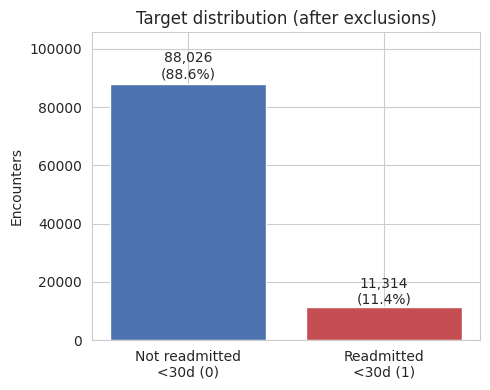

In [13]:
# ==============================================================================
# SECTION: EDA: target distribution
# Counts and plots readmitted vs. not readmitted to show the class imbalance.
# ==============================================================================
df_eda = X.copy()
df_eda["readmitted_30d"] = y.values

counts = y.value_counts().sort_index()
print(counts.to_string())
print((100 * y.value_counts(normalize=True)).round(2).to_string())

fig, ax = plt.subplots(figsize=(5, 4))
ax.bar(["Not readmitted\n<30d (0)", "Readmitted\n<30d (1)"], counts.values, color=["#4C72B0", "#C44E52"])
for i, v in enumerate(counts.values):
    ax.text(i, v * 1.01, f"{v:,}\n({100*v/len(y):.1f}%)", ha="center", va="bottom")
ax.set_ylim(0, counts.max() * 1.2)
ax.set_ylabel("Encounters"); ax.set_title("Target distribution (after exclusions)")
plt.tight_layout(); save_fig()

**What it shows:** ~11.4% of encounters are followed by a 30-day readmission. **Pattern:** ~8:1 imbalance. **Why it matters:** a model
that always predicts "no readmission" is already ~88.6% accurate, so accuracy is a misleading metric. **Implication:** every
model is class-weighted and judged on ROC-AUC, PR-AUC and recall rather than accuracy.

readmitted_30d          0      1
time_in_hospital     4.33   4.77
num_lab_procedures  42.74  44.22
num_procedures       1.34   1.28
num_medications     15.86  16.91
number_outpatient    0.36   0.44
number_emergency     0.18   0.36
number_inpatient     0.55   1.22
number_diagnoses     7.36   7.69


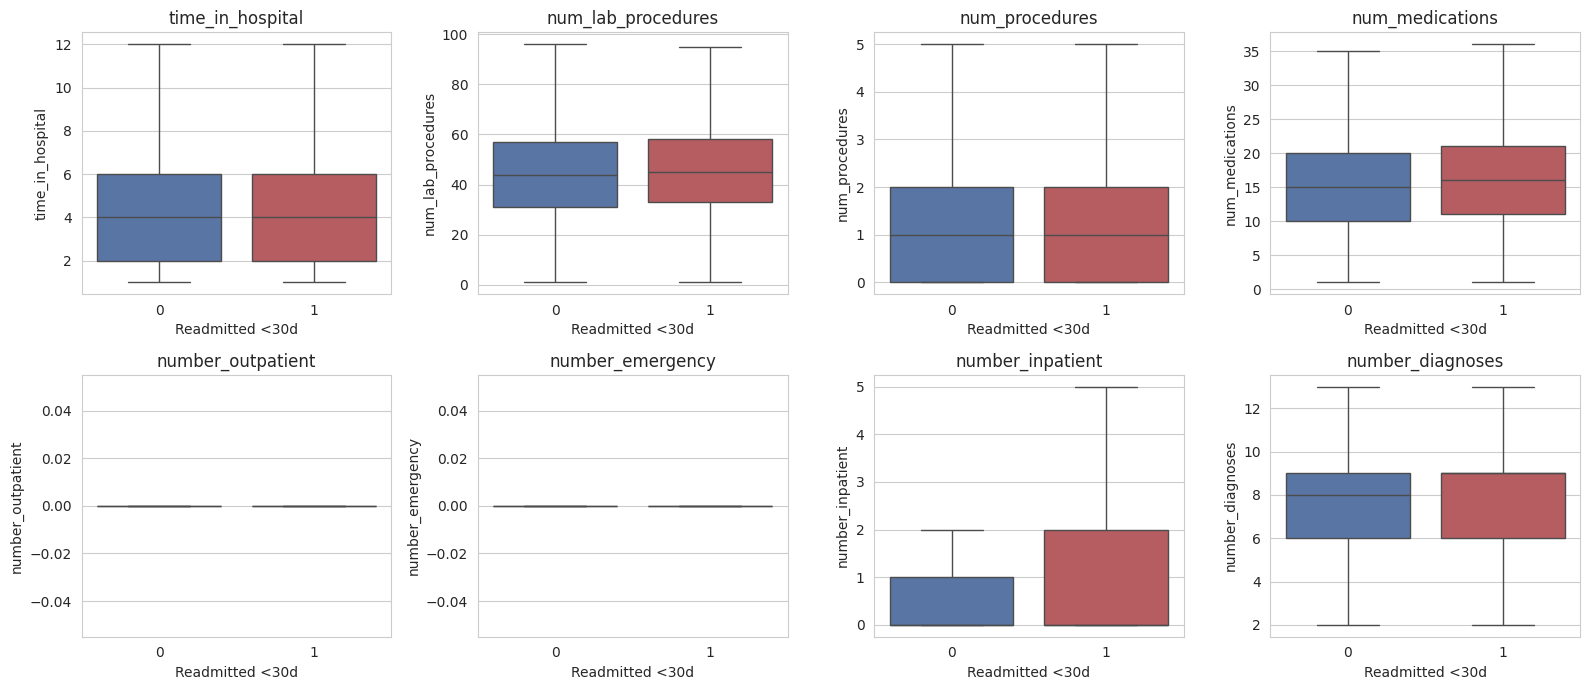

In [14]:
# ==============================================================================
# SECTION: EDA: numeric features by outcome
# Box plots and group means of each numeric feature for readmitted vs. not
# readmitted patients.
# ==============================================================================
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, col in zip(axes.flat, num_cols):
    sns.boxplot(x="readmitted_30d", y=col, data=df_eda, ax=ax, showfliers=False,
                hue="readmitted_30d", palette=["#4C72B0", "#C44E52"], legend=False)
    ax.set_title(col); ax.set_xlabel("Readmitted <30d")
plt.tight_layout(); save_fig()
print(df_eda.groupby("readmitted_30d")[num_cols].mean().round(2).T.to_string())

**What it shows:** each numeric feature for patients readmitted within 30 days (1) vs. not (0), with group means printed. **Pattern:**
`number_inpatient` (mean 1.22 vs. 0.55) and `number_emergency` (0.36 vs. 0.18) show the clearest shifts, with smaller ones for `time_in_hospital`, `num_medications` and `number_diagnoses`; `num_procedures` is slightly *lower* in the readmitted group.
**Why it matters:** an association, not proof of cause. **Implication:** prior utilization is expected to be an important
feature; tree models handle the skew natively and the logistic baseline uses standardized values.

Strongest pairs (|r|):
time_in_hospital  num_medications       0.464
num_procedures    num_medications       0.382
time_in_hospital  num_lab_procedures    0.320
number_emergency  number_inpatient      0.268


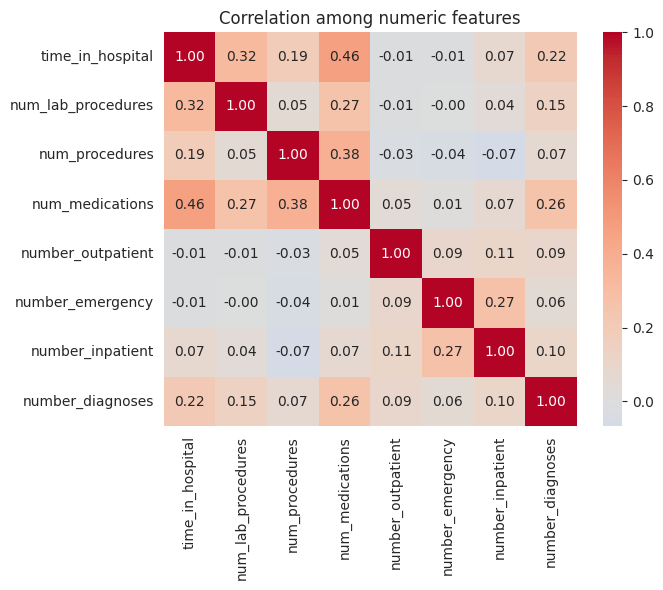

In [15]:
# ==============================================================================
# SECTION: EDA: correlation between numeric features
# Heatmap of Pearson correlations; prints the strongest pairs to check for
# collinearity.
# ==============================================================================
corr = df_eda[num_cols].corr()
fig, ax = plt.subplots(figsize=(7, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax)
ax.set_title("Correlation among numeric features")
plt.tight_layout(); save_fig()
pairs = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack().abs().sort_values(ascending=False)
print("Strongest pairs (|r|):")
print(pairs.head(4).round(3).to_string())

**What it shows:** pairwise Pearson correlation. **Pattern:** the strongest pair is `num_medications` vs. `time_in_hospital`
(r ≈ 0.46); none reaches 0.5. **Why it matters:** correlation is association, not causation, and moderate overlap
(longer stays → more medications) is clinically sensible. **Implication:** no feature is dropped for multicollinearity.

           rate      n
age                   
[0-10)    0.019    160
[10-20)   0.058    690
[20-30)   0.143   1649
[30-40)   0.113   3764
[40-50)   0.107   9607
[50-60)   0.098  17060
[60-70)   0.113  22058
[70-80)   0.121  25329
[80-90)   0.126  16434
[90-100)  0.119   2589


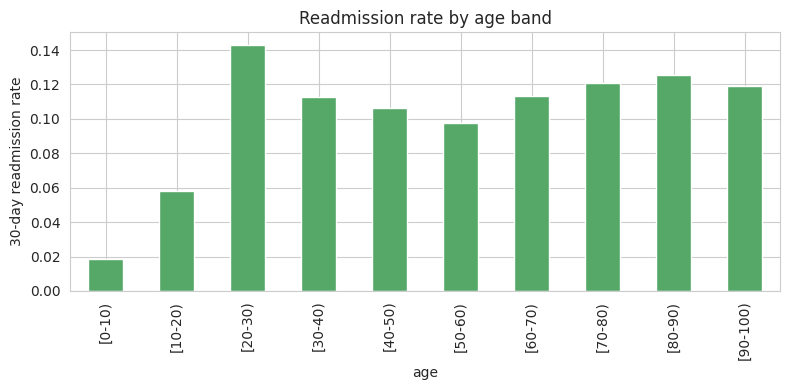

In [16]:
# ==============================================================================
# SECTION: EDA: readmission rate by age band
# Bar chart and table of the 30-day readmission rate for each age group.
# ==============================================================================
age_order = sorted(df_eda["age"].unique(), key=lambda s: int(s.strip("[)").split("-")[0]))
rate_age = df_eda.groupby("age")["readmitted_30d"].mean().reindex(age_order)
n_age = df_eda["age"].value_counts().reindex(age_order)
fig, ax = plt.subplots(figsize=(8, 4))
rate_age.plot(kind="bar", ax=ax, color="#55A868")
ax.set_ylabel("30-day readmission rate"); ax.set_title("Readmission rate by age band")
plt.tight_layout(); save_fig()
print(pd.DataFrame({"rate": rate_age.round(3), "n": n_age}).to_string())

**What it shows:** readmission rate per age band (with counts). **Pattern:** *non-monotonic* — very low for children, highest (14.3%) in the
small [20–30) group, a dip around [50–60), then ~11–13% from the 60s up. **Why it matters:** age carries signal but is not
a dominant, simple driver, and the youngest bands are small. **Implication:** `age` is kept as a categorical band, not a numeric slope.

                          mean   size
number_inpatient_capped              
0                        0.086  66242
1                        0.133  18984
2                        0.179   7300
3                        0.210   3271
4                        0.241   1574
5                        0.371   1969


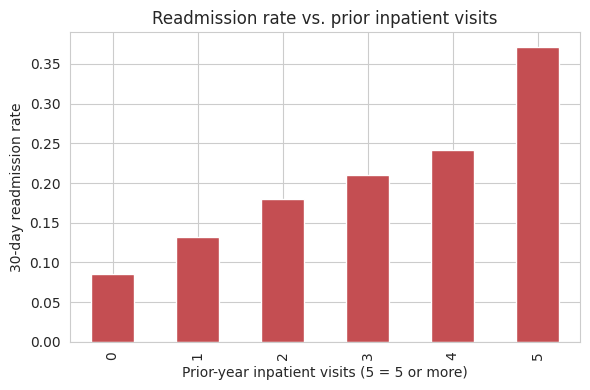

In [17]:
# ==============================================================================
# SECTION: EDA: readmission rate by prior inpatient visits
# Caps visits at 5 and plots the readmission rate; shows the strongest
# relationship in the data.
# ==============================================================================
df_eda["number_inpatient_capped"] = df_eda["number_inpatient"].clip(upper=5)
rate_inp = df_eda.groupby("number_inpatient_capped")["readmitted_30d"].agg(["mean", "size"])
fig, ax = plt.subplots(figsize=(6, 4))
rate_inp["mean"].plot(kind="bar", ax=ax, color="#C44E52")
ax.set_xlabel("Prior-year inpatient visits (5 = 5 or more)"); ax.set_ylabel("30-day readmission rate")
ax.set_title("Readmission rate vs. prior inpatient visits")
plt.tight_layout(); save_fig()
print(rate_inp.round(3).to_string())

**What it shows:** readmission rate by prior-year inpatient visits. **Pattern:** a clean, strong, monotonic rise from ~8.6% (0 visits) to ~37%
(5+). **Why it matters:** the clearest signal in the data and, as Task 7 confirms, the model's top feature. **Implication:** prior
utilization drives the model — and it is uninformative for patients with no prior admissions (see error analysis).

                  mean   size
diag_1_group                 
Missing          0.250     20
Diabetes         0.131   8661
Injury           0.124   6851
Circulatory      0.117  29680
Other            0.117  17793
Genitourinary    0.110   5002
Neoplasms        0.109   3131
Digestive        0.108   9333
Respiratory      0.101  13934
Musculoskeletal  0.095   4935


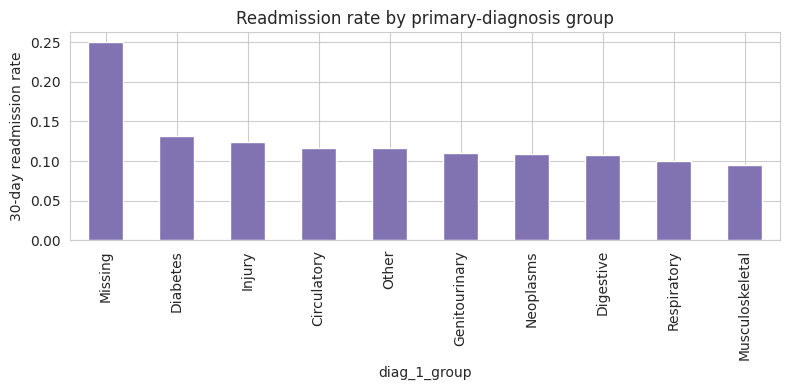

In [18]:
# ==============================================================================
# SECTION: EDA: readmission rate by primary diagnosis group
# Compares readmission rates across the engineered diagnosis groups.
# ==============================================================================
rate_diag = df_eda.groupby("diag_1_group")["readmitted_30d"].agg(["mean", "size"]).sort_values("mean", ascending=False)
fig, ax = plt.subplots(figsize=(8, 4))
rate_diag["mean"].plot(kind="bar", ax=ax, color="#8172B2")
ax.set_ylabel("30-day readmission rate"); ax.set_title("Readmission rate by primary-diagnosis group")
plt.tight_layout(); save_fig()
print(rate_diag.round(3).to_string())

**What it shows:** rate by engineered diagnosis group (the `Missing` group has only 20 rows, so its rate is unreliable). **Pattern:** a modest
spread among real groups (about 9.5% to 13%), Diabetes highest. **Why it matters:** diagnosis group is a secondary signal.
**Implication:** kept as a categorical feature among many.

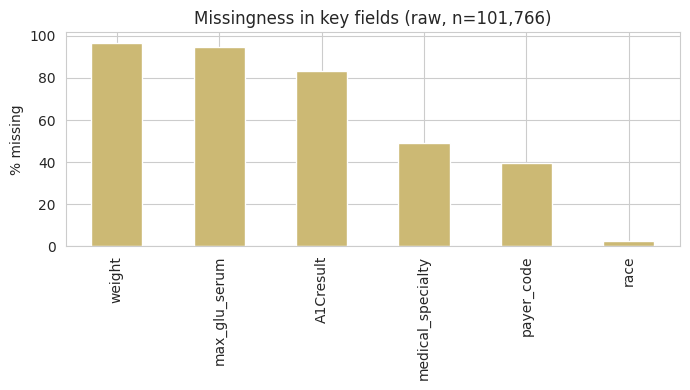

In [19]:
# ==============================================================================
# SECTION: EDA: missingness chart
# Bar chart of the percentage missing in key raw columns.
# ==============================================================================
miss = {c: 100 * (raw[c].astype(str) == "?").mean() for c in ["weight", "payer_code", "medical_specialty", "race"]}
miss.update({c: 100 * raw[c].isna().mean() for c in ["max_glu_serum", "A1Cresult"]})
fig, ax = plt.subplots(figsize=(7, 4))
pd.Series(miss).sort_values(ascending=False).plot(kind="bar", ax=ax, color="#CCB974")
ax.set_ylabel("% missing"); ax.set_title(f"Missingness in key fields (raw, n={len(raw):,})")
plt.tight_layout(); save_fig()

**What it shows:** the Task 3.1 missingness numbers. **Implication:** justifies dropping `weight` and using explicit "Unknown"/"Not tested"
categories (deleting rows would discard ~40–95% of the data).

A1Cresult
>7            0.1015
>8            0.0994
Norm          0.0977
Not tested    0.1169
insulin
Down      0.1422
No        0.1021
Steady    0.1137
Up        0.1333


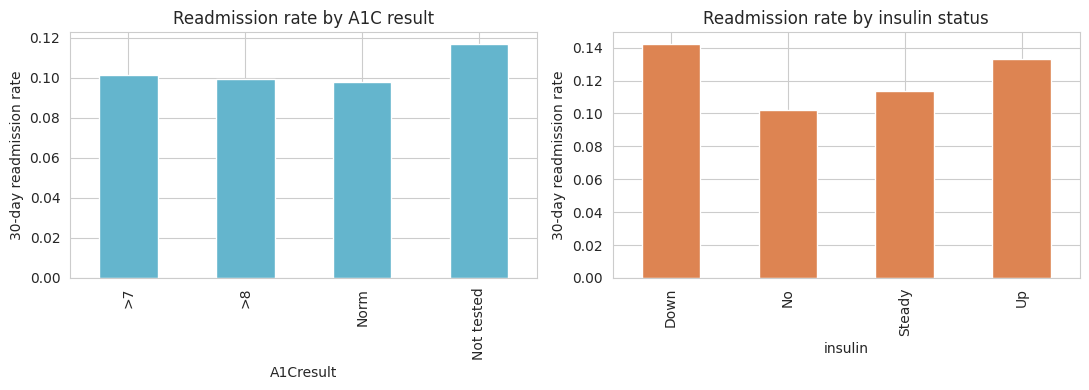

In [20]:
# ==============================================================================
# SECTION: EDA: A1C test and insulin status vs. readmission
# Compares readmission rates by A1C result and by insulin change.
# ==============================================================================
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
a1c = df_eda.groupby("A1Cresult")["readmitted_30d"].mean()
a1c.plot(kind="bar", ax=axes[0], color="#64B5CD"); axes[0].set_title("Readmission rate by A1C result")
ins = df_eda.groupby("insulin")["readmitted_30d"].mean()
ins.plot(kind="bar", ax=axes[1], color="#DD8452"); axes[1].set_title("Readmission rate by insulin status")
for ax in axes: ax.set_ylabel("30-day readmission rate")
plt.tight_layout(); save_fig()
print(a1c.round(4).to_string()); print(ins.round(4).to_string())

**What it shows:** readmission by A1C testing and insulin status. **Pattern:** patients *not tested* for A1C have a higher rate (~11.7%) than those
tested (~10%), echoing the original Strack et al. (2014) interest in testing practice; insulin "Down"/"Up" changes show higher rates than "No".
**Why it matters:** these are practice/acuity associations, not evidence that ordering tests or changing insulin would cause
fewer readmissions. **Implication:** both stay as categorical features with "Not tested" kept explicit.

## Descriptive statistics and distributions
Variable types: 8 numeric (counts/days), 38 categorical. Missing values are handled in Task 3 (none remain in the numeric columns).

In [21]:
# ==============================================================================
# SECTION: EDA: descriptive statistics
# Mean, median, min, max, standard deviation and missing count for each
# numeric feature.
# ==============================================================================
stats = df_eda[num_cols].agg(["mean", "median", "min", "max", "std"]).T.round(2)
stats["missing"] = df_eda[num_cols].isna().sum()
stats

,mean,median,min,max,std,missing
time_in_hospital,4.38,4.0,1.0,14.0,2.97,0
num_lab_procedures,42.91,44.0,1.0,132.0,19.61,0
num_procedures,1.33,1.0,0.0,6.0,1.70,0
num_medications,15.98,15.0,1.0,81.0,8.09,0
number_outpatient,0.37,0.0,0.0,42.0,1.27,0
number_emergency,0.20,0.0,0.0,76.0,0.94,0
number_inpatient,0.63,0.0,0.0,21.0,1.26,0
number_diagnoses,7.40,8.0,1.0,16.0,1.94,0


**What it tells us.** Means exceed medians for the visit-count columns (`number_outpatient`, `number_emergency`, `number_inpatient`) and the maxima are far above the medians: heavily right-skewed, with a small group of very frequent users.
Length of stay is 1–14 days (it is capped in this dataset). This supports keeping outliers and using tree models / scaling rather than trimming.

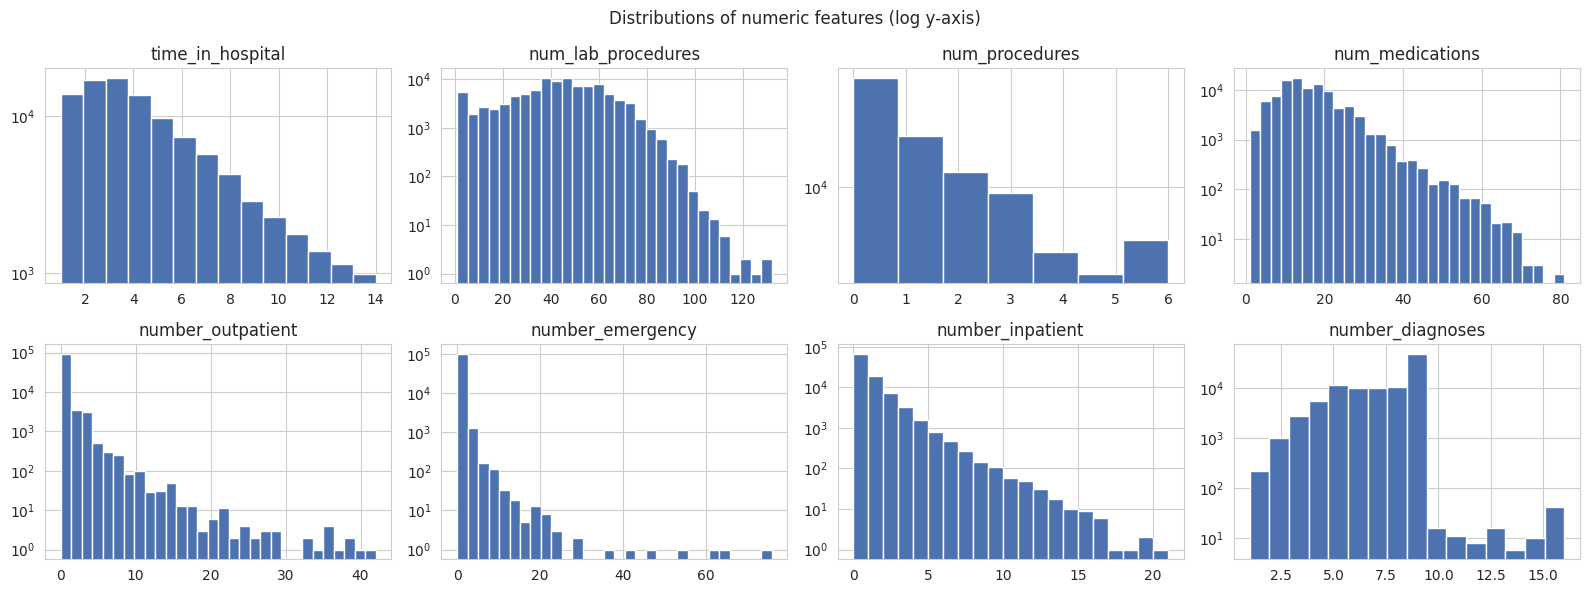

In [22]:
# ==============================================================================
# SECTION: EDA: histograms
# Histograms (log y-axis) of the numeric features to show skew and extreme
# values.
# ==============================================================================
fig, axes = plt.subplots(2, 4, figsize=(16, 6))
for ax, col in zip(axes.flat, num_cols):
    ax.hist(df_eda[col], bins=min(30, int(df_eda[col].nunique())), color="#4C72B0")
    ax.set_title(col); ax.set_yscale("log")
fig.suptitle("Distributions of numeric features (log y-axis)")
plt.tight_layout(); save_fig()

**What it shows:** histograms (log y-axis so the long tails are visible). **Pattern:** utilization counts pile up at 0–1 with long right tails; `time_in_hospital` and `number_diagnoses` are more spread out.
**Implication:** confirms skew and extreme values noted above; no value is impossible (no negatives), so none is removed.

## EDA findings and summary

| Finding | Evidence | Possible impact on modeling |
|---|---|---|
| Target is imbalanced (~11% positive) | Target-distribution chart | Use class weights; judge by ROC-AUC / PR-AUC / recall, not accuracy |
| Prior inpatient visits strongly track readmission | Rate rises from ~8.6% (0 visits) to ~37% (5+) | Expected top feature; weak for first-time patients (see error analysis) |
| Emergency visits and length of stay differ modestly by outcome | Group-mean table / box plots | Keep as numeric features |
| Age effect is non-monotonic | Rate by age band | Keep age as a categorical band, not a slope |
| Numeric features only moderately correlated | Largest absolute correlation r ≈ 0.46 (medications vs. stay) | No feature dropped for collinearity |
| A1C "not tested" has a higher rate than tested | Rate by A1C result | Keep "Not tested" as its own category; association, not cause |
| `weight` ~97% missing, `payer_code` ~40%, `medical_specialty` ~49% | Missingness chart | Drop `weight`; explicit "Unknown" for the others |
| 23.5% of patients have more than one encounter | Task 3.1 | Patient-level split mandatory (leakage risk) |

**EDA summary.** The most informative variables are prior-year utilization (especially `number_inpatient`) followed by discharge disposition and length of stay. Quality issues found and fixed: a 97%-missing column, `?` placeholders,
blank lab results that mean "not tested", 3 invalid genders, expired/hospice discharges that cannot be readmitted, and repeat patients. Keep in mind while modeling: class imbalance (weights, correct metrics),
leakage (patient-grouped split, no identifiers, exclusions), and the modest overall signal (expect modest AUC, not near-perfect).

# Task 5 — Build a Baseline Model

**Baseline: class-weighted Logistic Regression** inside a `Pipeline` with the shared preprocessor (fit on training data only).

In [23]:
# ==============================================================================
# SECTION: Baseline model: Logistic Regression
# Builds preprocessing + class-weighted Logistic Regression, trains on the
# training set and reports validation metrics.
# ==============================================================================
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

baseline_pipe = Pipeline([("prep", build_preprocessor()),
                          ("clf", LogisticRegression(max_iter=1000, class_weight="balanced", random_state=RANDOM_SEED))])
t0 = time.time()
baseline_pipe.fit(X_train, y_train)
print("Baseline training time (s):", round(time.time() - t0, 2))
baseline_val_prob = baseline_pipe.predict_proba(X_val)[:, 1]
baseline_val_metrics = evaluate(y_val, baseline_val_prob, 0.5)
print(json.dumps(baseline_val_metrics, indent=2))

Baseline training time (s): 26.5
{
  "roc_auc": 0.6673,
  "pr_auc": 0.2228,
  "recall": 0.5471,
  "precision": 0.1854,
  "f1": 0.277,
  "accuracy": 0.6699,
  "confusion_matrix": [
    [
      9020,
      4130
    ],
    [
      778,
      940
    ]
  ],
  "threshold_used": 0.5,
  "brier_score": 0.2242
}


**Discussion.** The baseline is clearly better than chance (ROC-AUC 0.50), so the problem has learnable signal. At the default 0.5 threshold it catches
a bit over half of true readmissions (recall ≈ 0.55) but with low precision (≈ 0.18): most flags are false alarms, the usual price of
a rare outcome. This is the reference every later model and threshold choice is compared against.

### Trivial reference and baseline summary
The guideline asks for a comparison against a trivial model. A "majority-class" model that always predicts *no readmission* is built below.

In [24]:
# ==============================================================================
# SECTION: Trivial reference model
# Always predicts 'no readmission'; compared with the baseline to show why
# accuracy alone is misleading.
# ==============================================================================
from sklearn.dummy import DummyClassifier
dummy = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
dummy_prob = dummy.predict_proba(X_val)[:, 1]
dummy_m = evaluate(y_val, dummy_prob, 0.5)
base_table = pd.DataFrame({"Always predict 'no readmission' (trivial)": dummy_m, "Logistic Regression (baseline)": baseline_val_metrics}).T
base_table = base_table[["accuracy", "roc_auc", "pr_auc", "recall", "precision", "f1"]]
base_table["Notes"] = ["High accuracy but finds 0 readmissions; AUC = chance", "Lower accuracy, but catches over half of true readmissions; AUC clearly above chance"]
base_table

,accuracy,roc_auc,pr_auc,recall,precision,f1,Notes
Always predict 'no readmission' (trivial),0.8844,0.5,0.1156,0.0,0.0,0.0,High accuracy but finds 0 readmissions; AUC = ...
Logistic Regression (baseline),0.6699,0.6673,0.2228,0.5471,0.1854,0.277,"Lower accuracy, but catches over half of true ..."


**Why logistic regression?** It fits a binary outcome with many one-hot features, trains in seconds on ~70K rows, gives interpretable coefficients, and is the standard benchmark for tabular classification. Its limits: it cannot
capture interactions or non-linear effects automatically. **Reading the table:** the trivial model is ~88% accurate yet useless (recall 0), so accuracy is not the metric to trust; the baseline beats chance on ROC-AUC/PR-AUC and recall.
Features, target, training data and evaluation data are kept separate (fit on train, scored on validation).

# Task 6 — Improve the Model

## 6.1 Random Forest (alternative / fallback)

In [25]:
# ==============================================================================
# SECTION: Improved model 1: Random Forest
# Trains a class-weighted Random Forest and reports validation metrics.
# ==============================================================================
from sklearn.ensemble import RandomForestClassifier

rf_pipe = Pipeline([("prep", build_preprocessor()),
                    ("clf", RandomForestClassifier(n_estimators=200, max_depth=10, class_weight="balanced_subsample",
                                                    random_state=RANDOM_SEED, n_jobs=1))])
t0 = time.time()
rf_pipe.fit(X_train, y_train)
print("Random Forest training time (s):", round(time.time() - t0, 2))
rf_val_prob = rf_pipe.predict_proba(X_val)[:, 1]
rf_val_metrics = evaluate(y_val, rf_val_prob, 0.5)
print(json.dumps(rf_val_metrics, indent=2))

Random Forest training time (s): 28.89
{
  "roc_auc": 0.6643,
  "pr_auc": 0.2102,
  "recall": 0.5221,
  "precision": 0.1868,
  "f1": 0.2752,
  "accuracy": 0.6821,
  "confusion_matrix": [
    [
      9245,
      3905
    ],
    [
      821,
      897
    ]
  ],
  "threshold_used": 0.5,
  "brier_score": 0.2218
}


## 6.2 HistGradientBoostingClassifier — primary candidate, tuned

`RandomizedSearchCV` (6 sampled configurations, ROC-AUC) with `StratifiedGroupKFold` (3 folds grouped by `patient_nbr`) on the **training split only**, so a
patient never appears on both sides of any CV fold. The search is deliberately small (6 × 3 = 18 fits) because the build machine has one CPU core and a
300-second per-command limit; a larger search is listed as future work.

In [26]:
# ==============================================================================
# SECTION: Improved model 2: HistGradientBoosting with tuning
# Randomized hyper-parameter search with patient-grouped 3-fold cross-
# validation on the training set; keeps the best model and reports validation
# metrics.
# ==============================================================================
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.model_selection import StratifiedGroupKFold, RandomizedSearchCV

param_dist = {
    "clf__learning_rate": [0.05, 0.08, 0.1],
    "clf__max_leaf_nodes": [15, 31, 63],
    "clf__max_depth": [4, 6, None],
    "clf__min_samples_leaf": [20, 50, 100],
    "clf__l2_regularization": [0.0, 0.5, 1.0],
}
hgb_pipe = Pipeline([("prep", build_preprocessor()),
                     ("clf", HistGradientBoostingClassifier(random_state=RANDOM_SEED, class_weight="balanced", max_iter=150))])
cv = StratifiedGroupKFold(n_splits=3, shuffle=True, random_state=RANDOM_SEED)
search = RandomizedSearchCV(hgb_pipe, param_dist, n_iter=6, scoring="roc_auc", cv=cv,
                            random_state=RANDOM_SEED, n_jobs=1, refit=True)
t0 = time.time()
search.fit(X_train, y_train, groups=g_train)
print("Search time (s):", round(time.time() - t0, 1))
print("Best params :", search.best_params_)
print("Best CV ROC-AUC:", round(search.best_score_, 4))

hgb_best = search.best_estimator_
hgb_val_prob = hgb_best.predict_proba(X_val)[:, 1]
hgb_val_metrics = evaluate(y_val, hgb_val_prob, 0.5)
cv_table = pd.DataFrame(search.cv_results_)[["params", "mean_test_score", "std_test_score"]].round(4)
cv_table = cv_table.sort_values("mean_test_score", ascending=False)
print("\nAll sampled configurations (mean CV ROC-AUC):")
print(cv_table.to_string(index=False))

Search time (s): 219.6
Best params : {'clf__min_samples_leaf': 50, 'clf__max_leaf_nodes': 31, 'clf__max_depth': None, 'clf__learning_rate': 0.1, 'clf__l2_regularization': 1.0}
Best CV ROC-AUC: 0.6661

All sampled configurations (mean CV ROC-AUC):
                                                                                                                                     params  mean_test_score  std_test_score
 {'clf__min_samples_leaf': 50, 'clf__max_leaf_nodes': 31, 'clf__max_depth': None, 'clf__learning_rate': 0.1, 'clf__l2_regularization': 1.0}           0.6661          0.0044
   {'clf__min_samples_leaf': 100, 'clf__max_leaf_nodes': 63, 'clf__max_depth': 6, 'clf__learning_rate': 0.1, 'clf__l2_regularization': 0.5}           0.6651          0.0047
   {'clf__min_samples_leaf': 50, 'clf__max_leaf_nodes': 31, 'clf__max_depth': 6, 'clf__learning_rate': 0.05, 'clf__l2_regularization': 1.0}           0.6648          0.0049
   {'clf__min_samples_leaf': 20, 'clf__max_leaf_nodes': 63, '

### Tuning log and overfitting check

In [27]:
# ==============================================================================
# SECTION: Tuning log
# Shows each tuned parameter before (sklearn default) and after, with the
# reason.
# ==============================================================================
defaults = HistGradientBoostingClassifier().get_params()
tuning_log = pd.DataFrame([
    (k.replace("clf__", ""), str(defaults.get(k.replace("clf__", ""))) if k.replace("clf__", "") != "learning_rate" else "0.1 (default)", str(v),
     "Chosen by 3-fold patient-grouped CV ROC-AUC")
    for k, v in search.best_params_.items()
] + [("max_iter", str(defaults["max_iter"]), "150", "Fixed (runtime budget); not tuned"),
     ("class_weight", "None", "balanced", "Handles the ~11% positive rate (training data only)")],
    columns=["Parameter", "Before (sklearn default)", "After", "Reason"])
tuning_log

,Parameter,Before (sklearn default),After,Reason
0,min_samples_leaf,20,50,Chosen by 3-fold patient-grouped CV ROC-AUC
1,max_leaf_nodes,31,31,Chosen by 3-fold patient-grouped CV ROC-AUC
2,max_depth,None,None,Chosen by 3-fold patient-grouped CV ROC-AUC
3,learning_rate,0.1 (default),0.1,Chosen by 3-fold patient-grouped CV ROC-AUC
4,l2_regularization,0.0,1.0,Chosen by 3-fold patient-grouped CV ROC-AUC
5,max_iter,100,150,Fixed (runtime budget); not tuned
6,class_weight,None,balanced,Handles the ~11% positive rate (training data ...


In [28]:
# ==============================================================================
# SECTION: Overfitting check
# Compares training and validation ROC-AUC for each model; a large gap means
# the model memorizes the training data.
# ==============================================================================
# Overfitting check: training vs. validation ROC-AUC for each model (a large gap would need investigation)
of_rows = []
for name, mdl in [("LogisticRegression (baseline)", baseline_pipe), ("RandomForest", rf_pipe), ("HistGradientBoosting (tuned)", hgb_best)]:
    tr_auc = roc_auc_score(y_train, mdl.predict_proba(X_train)[:, 1])
    va_auc = roc_auc_score(y_val, mdl.predict_proba(X_val)[:, 1])
    of_rows.append((name, round(tr_auc, 4), round(va_auc, 4), round(tr_auc - va_auc, 4)))
pd.DataFrame(of_rows, columns=["Model", "Train ROC-AUC", "Validation ROC-AUC", "Gap"])

,Model,Train ROC-AUC,Validation ROC-AUC,Gap
0,LogisticRegression (baseline),0.6744,0.6673,0.0072
1,RandomForest,0.7484,0.6643,0.0840
2,HistGradientBoosting (tuned),0.7240,0.6673,0.0567


**Reading it.** The gap between training and validation AUC shows how much each model memorizes: a small gap means little overfitting; a larger one (typically Random Forest, deeper trees) means the model fits training patients better than unseen ones.
No model here shows the dramatic "98% vs 71%" kind of gap, but the Random Forest gap is the one to watch; the validation score is what model choice is based on.

**Experiments that did not help (kept on purpose).**
- *Random Forest* scored slightly **below** the logistic baseline on validation ROC-AUC — more model complexity did not help here.
- The *boosted-tree models* gave at most a small gain over the logistic baseline on validation ROC-AUC (see the comparison table in 6.3); the Module 4 target of a ≥5% improvement is checked against the test set in Task 7.
- *Absolute risk-tier cut points* (0.10 / 0.30, chosen before seeing the scores) were meaningless because class weighting inflates scores; they were replaced by percentile-based cut points computed on validation scores (Task 8).
- The hyperparameter search is small (6 configurations) because of runtime limits; a larger search was not tried.

## 6.2b XGBoost and LightGBM — additional candidates **[Colab only]**
The Module 4 plan named XGBoost (primary) and LightGBM (additional). Both are trained here with the same preprocessor, the same patient-level split, class weighting,
and a **fixed, untuned** configuration (no search — to keep runtime short). Their validation scores are shown next to the executed models in 6.3.
If a package is missing, the cell prints "skipped".

In [29]:
# ==============================================================================
# SECTION: Extra candidates: XGBoost and LightGBM (Colab)
# Trains XGBoost and LightGBM with fixed settings and class weighting; skipped
# if the packages are missing.
# ==============================================================================
from sklearn.pipeline import Pipeline
extra_models, extra_val_prob = {}, {}
n_neg, n_pos = int((y_train == 0).sum()), int((y_train == 1).sum())

if HAS_XGB:
    from xgboost import XGBClassifier
    xgb_pipe = Pipeline([("prep", build_preprocessor()),
                         ("clf", XGBClassifier(n_estimators=300, learning_rate=0.05, max_depth=4, subsample=0.8, colsample_bytree=0.8,
                                               scale_pos_weight=n_neg / n_pos, tree_method="hist", eval_metric="auc",
                                               n_jobs=-1, random_state=RANDOM_SEED))])
    t0 = time.time(); xgb_pipe.fit(X_train, y_train)
    extra_models["XGBoost"] = xgb_pipe; extra_val_prob["XGBoost"] = xgb_pipe.predict_proba(X_val)[:, 1]
    print(f"XGBoost trained in {time.time()-t0:.1f}s")
else:
    print("XGBoost skipped (package not available in this runtime).")

if HAS_LGBM:
    from lightgbm import LGBMClassifier
    lgbm_pipe = Pipeline([("prep", build_preprocessor()),
                          ("clf", LGBMClassifier(n_estimators=300, learning_rate=0.05, num_leaves=31, subsample=0.8, subsample_freq=1,
                                                 colsample_bytree=0.8, class_weight="balanced", n_jobs=-1, random_state=RANDOM_SEED, verbose=-1))])
    t0 = time.time(); lgbm_pipe.fit(X_train, y_train)
    extra_models["LightGBM"] = lgbm_pipe; extra_val_prob["LightGBM"] = lgbm_pipe.predict_proba(X_val)[:, 1]
    print(f"LightGBM trained in {time.time()-t0:.1f}s")
else:
    print("LightGBM skipped (package not available in this runtime).")

if extra_val_prob:
    print(pd.DataFrame({k: evaluate(y_val, p, 0.5) for k, p in extra_val_prob.items()}).T[["roc_auc", "pr_auc", "recall", "precision", "f1", "brier_score"]].to_string())

XGBoost trained in 12.6s
LightGBM trained in 5.4s
         roc_auc  pr_auc  recall precision      f1 brier_score
XGBoost   0.6739  0.2332  0.5675    0.1868  0.2811      0.2169
LightGBM  0.6743  0.2378  0.5262    0.1944  0.2839       0.204


## 6.3 Model comparison (validation set) and model selection

Selected model (highest validation ROC-AUC): LightGBM


,roc_auc,pr_auc,recall,precision,f1,accuracy,brier_score
LogisticRegression (baseline),0.6673,0.2228,0.5471,0.1854,0.2770,0.6699,0.2242
RandomForest,0.6643,0.2102,0.5221,0.1868,0.2752,0.6821,0.2218
HistGradientBoosting (tuned),0.6673,0.2270,0.5501,0.1806,0.2719,0.6597,0.2174
XGBoost,0.6739,0.2332,0.5675,0.1868,0.2811,0.6646,0.2169
LightGBM,0.6743,0.2378,0.5262,0.1944,0.2839,0.6933,0.2040


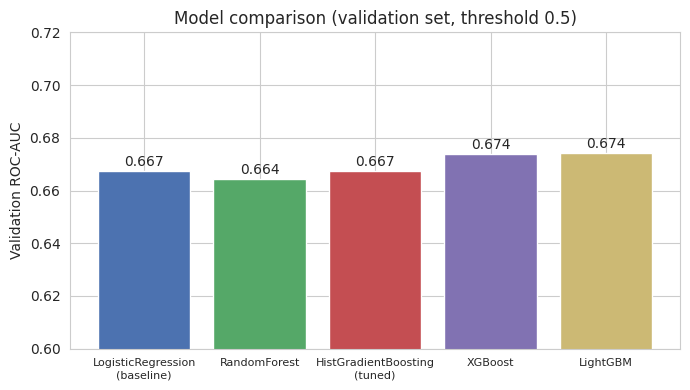

In [30]:
# ==============================================================================
# SECTION: Model comparison and selection
# Puts all candidates in one table, chooses the model with the highest
# validation ROC-AUC, and plots the comparison.
# ==============================================================================
candidates = {
    "LogisticRegression (baseline)": (baseline_pipe, baseline_val_prob),
    "RandomForest": (rf_pipe, rf_val_prob),
    "HistGradientBoosting (tuned)": (hgb_best, hgb_val_prob),
}
comparison = pd.DataFrame({name: evaluate(y_val, p, 0.5) for name, (m, p) in candidates.items()}).T
comparison = comparison[["roc_auc", "pr_auc", "recall", "precision", "f1", "accuracy", "brier_score"]].astype(float)

PROMOTE_EXTRA_TO_FINAL = True    # True = XGBoost/LightGBM (if installed) compete for the final model; False = only LogReg / RandomForest / HistGradientBoosting
if PROMOTE_EXTRA_TO_FINAL:
    for k in extra_models:
        candidates[k] = (extra_models[k], extra_val_prob[k])
comparison = pd.DataFrame({name: evaluate(y_val, p, 0.5) for name, (m, p) in candidates.items()}).T
comparison = comparison[["roc_auc", "pr_auc", "recall", "precision", "f1", "accuracy", "brier_score"]].astype(float)
best_name = comparison["roc_auc"].idxmax()          # selected on validation ROC-AUC only
final_pipe = candidates[best_name][0]
final_val_prob = candidates[best_name][1]
print("Selected model (highest validation ROC-AUC):", best_name)

fig, ax = plt.subplots(figsize=(7, 4))
# one bar per candidate: the 3 scikit-learn models, plus XGBoost / LightGBM when they take part (so the label count always matches the data)
palette = ["#4C72B0", "#55A868", "#C44E52", "#8172B2", "#CCB974", "#64B5CD"]
labels = [n.replace(" (", "\n(") for n in comparison.index]
bars = ax.bar(labels, comparison["roc_auc"].values, color=palette[:len(labels)])
plt.xticks(fontsize=8)
for b, v in zip(bars, comparison["roc_auc"].values):
    ax.text(b.get_x() + b.get_width() / 2, v + 0.002, f"{v:.3f}", ha="center")
ax.set_ylim(0.6, 0.72); ax.set_ylabel("Validation ROC-AUC"); ax.set_title("Model comparison (validation set, threshold 0.5)")
plt.tight_layout(); save_fig()
comparison

In [31]:
# ==============================================================================
# SECTION: Selection summary
# Prints the validation ranking and the margin between the best and second-
# best model.
# ==============================================================================
ranked = comparison["roc_auc"].sort_values(ascending=False)
print("Validation ROC-AUC ranking (threshold-independent):"); print(ranked.round(4).to_string())
margin = ranked.iloc[0] - ranked.iloc[1]
print(f"\nSelected: {best_name}  (margin over runner-up: {margin:.4f} ROC-AUC; ties go to the earlier-listed, simpler model)")
print("Differences of a few thousandths are within what library versions or random seeds can change, so read this as 'slightly better', not 'clearly better'.")

Validation ROC-AUC ranking (threshold-independent):
LightGBM                         0.6743
XGBoost                          0.6739
LogisticRegression (baseline)    0.6673
HistGradientBoosting (tuned)     0.6673
RandomForest                     0.6643

Selected: LightGBM  (margin over runner-up: 0.0004 ROC-AUC; ties go to the earlier-listed, simpler model)
Differences of a few thousandths are within what library versions or random seeds can change, so read this as 'slightly better', not 'clearly better'.


## 6.4 Class imbalance and threshold tuning

Imbalance is handled by **class weighting** inside every model (no resampling, so nothing synthetic can leak and validation/test keep the true class
distribution). The default 0.5 cut-off is not assumed optimal: thresholds 0.05–0.55 are swept on the **validation set only**, choosing the threshold with the
highest precision among those with recall ≥ 0.50 (the Module 4 recall target). The test set is not touched.

Chosen decision threshold: 0.51
threshold_used    0.5100
recall            0.5070
precision         0.2012
f1                0.2881


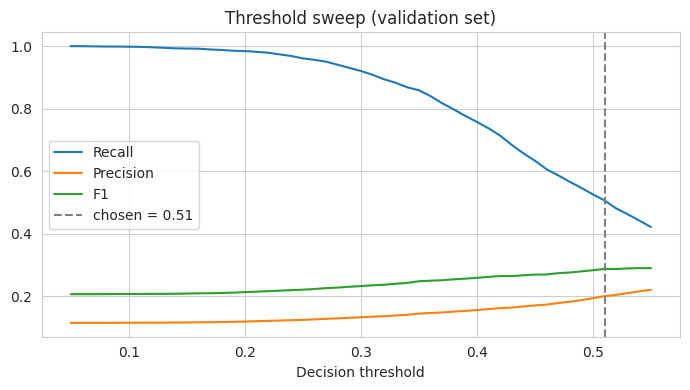

In [32]:
# ==============================================================================
# SECTION: Threshold tuning (validation set only)
# Tries thresholds from 0.05 to 0.55 and picks the one with the highest
# precision among those with recall >= 0.50.
# ==============================================================================
thresholds = np.round(np.arange(0.05, 0.56, 0.01), 2)
sweep = pd.DataFrame([evaluate(y_val, final_val_prob, t) for t in thresholds])[["threshold_used", "recall", "precision", "f1"]]

eligible = sweep[sweep["recall"] >= 0.50]
chosen_row = eligible.loc[eligible["precision"].idxmax()] if len(eligible) else sweep.loc[sweep["f1"].idxmax()]
final_threshold = float(chosen_row["threshold_used"])
print("Chosen decision threshold:", final_threshold)
print(chosen_row.round(4).to_string())

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(sweep["threshold_used"], sweep["recall"], label="Recall")
ax.plot(sweep["threshold_used"], sweep["precision"], label="Precision")
ax.plot(sweep["threshold_used"], sweep["f1"], label="F1")
ax.axvline(final_threshold, color="gray", ls="--", label=f"chosen = {final_threshold}")
ax.set_xlabel("Decision threshold"); ax.set_title("Threshold sweep (validation set)"); ax.legend()
plt.tight_layout(); save_fig()

## 6.5 Final-model decision
The candidates are close on validation ROC-AUC, so the choice weighs more than the top number. The table below is computed; the decision rule is stated after it.

In [33]:
# ==============================================================================
# SECTION: Final-model decision table
# Compares validation AUC, train-validation gap and prediction speed for each
# model and states the decision rule.
# ==============================================================================
dec_rows = []
for name, (mdl, pv) in candidates.items():
    tr_auc = roc_auc_score(y_train, mdl.predict_proba(X_train)[:, 1])
    t0 = time.perf_counter(); mdl.predict_proba(X_val.iloc[:1000]); ms = 1000 * (time.perf_counter() - t0) / 1000
    dec_rows.append((name, round(roc_auc_score(y_val, pv), 4), round(average_precision_score(y_val, pv), 4), round(tr_auc, 4),
                     round(tr_auc - roc_auc_score(y_val, pv), 4), round(ms, 3)))
decision = pd.DataFrame(dec_rows, columns=["Model", "Val ROC-AUC", "Val PR-AUC", "Train ROC-AUC", "Train-val gap", "ms per record (batch of 1000)"])
print(decision.to_string(index=False))
print(f"\nDecision rule: highest validation ROC-AUC. Selected: {best_name}.")
print("Interpretability: Logistic Regression is the easiest to explain (coefficients); tree models need permutation importance / SHAP.")
lr_auc = comparison.loc["LogisticRegression (baseline)", "roc_auc"]
if best_name != "LogisticRegression (baseline)" and comparison.loc[best_name, "roc_auc"] - lr_auc < 0.005:
    print(f"Note: the selected model beats the logistic baseline by only {comparison.loc[best_name, 'roc_auc'] - lr_auc:.4f} validation ROC-AUC; "
          "the simpler baseline would be a defensible alternative if the team prefers interpretability.")

                        Model  Val ROC-AUC  Val PR-AUC  Train ROC-AUC  Train-val gap  ms per record (batch of 1000)
LogisticRegression (baseline)       0.6673      0.2228         0.6744         0.0072                          0.036
                 RandomForest       0.6643      0.2102         0.7484         0.0840                          0.086
 HistGradientBoosting (tuned)       0.6673      0.2270         0.7240         0.0567                          0.037
                      XGBoost       0.6739      0.2332         0.7205         0.0466                          0.029
                     LightGBM       0.6743      0.2378         0.8036         0.1292                          0.036

Decision rule: highest validation ROC-AUC. Selected: LightGBM.
Interpretability: Logistic Regression is the easiest to explain (coefficients); tree models need permutation importance / SHAP.


# Task 7 — Evaluate the Model

The test set is evaluated **once**, with the model and threshold already fixed.

In [34]:
# ==============================================================================
# SECTION: FINAL EVALUATION on the test set (done once)
# Scores the untouched test set with the chosen model and threshold and prints
# all metrics.
# ==============================================================================
test_prob = final_pipe.predict_proba(X_test)[:, 1]
test_metrics = evaluate(y_test, test_prob, final_threshold)
print(json.dumps(test_metrics, indent=2))

{
  "roc_auc": 0.6856,
  "pr_auc": 0.239,
  "recall": 0.5289,
  "precision": 0.2014,
  "f1": 0.2917,
  "accuracy": 0.7095,
  "confusion_matrix": [
    [
      9653,
      3525
    ],
    [
      792,
      889
    ]
  ],
  "threshold_used": 0.51,
  "brier_score": 0.2028
}


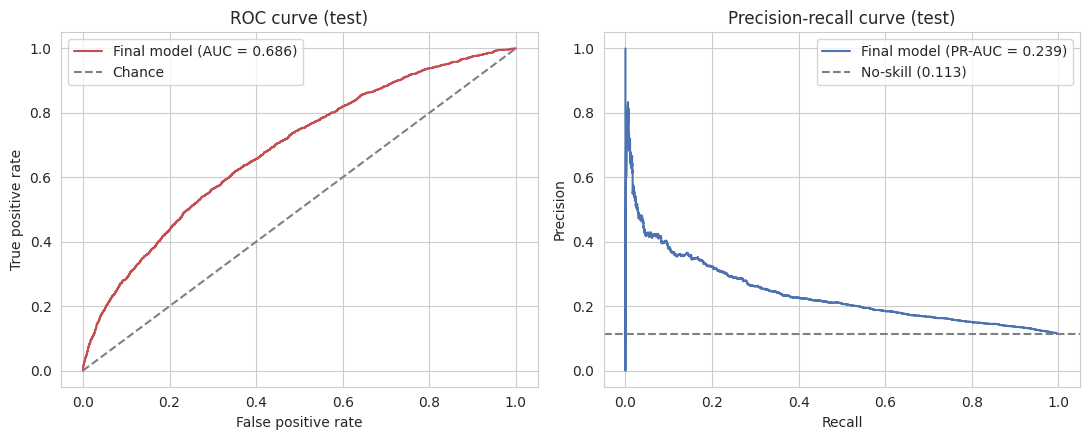

In [35]:
# ==============================================================================
# SECTION: ROC and precision-recall curves
# Plots how well the model separates the classes across thresholds, with the
# chance level for reference.
# ==============================================================================
fpr, tpr, _ = roc_curve(y_test, test_prob)
prec, rec, _ = precision_recall_curve(y_test, test_prob)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
axes[0].plot(fpr, tpr, color="#C44E52", label=f"Final model (AUC = {test_metrics['roc_auc']:.3f})")
axes[0].plot([0, 1], [0, 1], "--", color="gray", label="Chance")
axes[0].set_xlabel("False positive rate"); axes[0].set_ylabel("True positive rate"); axes[0].set_title("ROC curve (test)"); axes[0].legend()
axes[1].plot(rec, prec, color="#4C72B0", label=f"Final model (PR-AUC = {test_metrics['pr_auc']:.3f})")
axes[1].axhline(y_test.mean(), ls="--", color="gray", label=f"No-skill ({y_test.mean():.3f})")
axes[1].set_xlabel("Recall"); axes[1].set_ylabel("Precision"); axes[1].set_title("Precision-recall curve (test)"); axes[1].legend()
plt.tight_layout(); save_fig()

Model Brier score         : 0.2028
Trivial base-rate Brier   : 0.1003  (always predict the base rate)


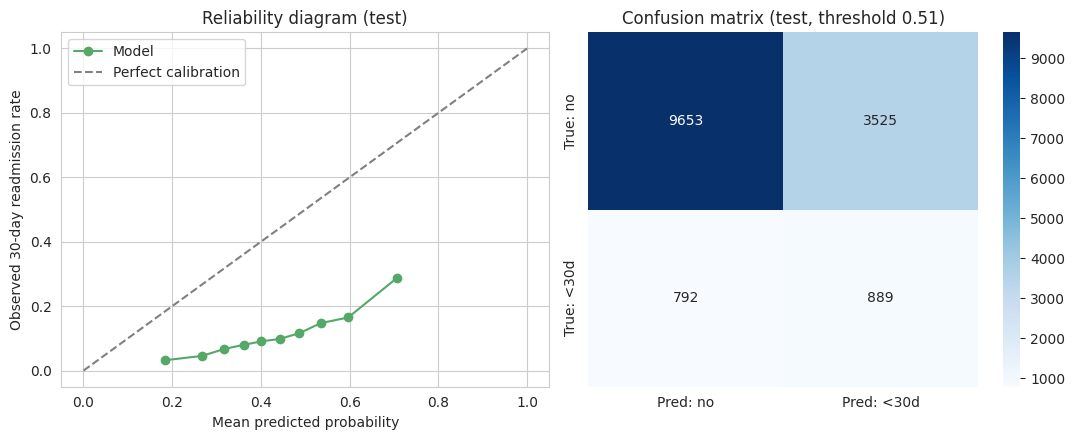

In [36]:
# ==============================================================================
# SECTION: Calibration and confusion matrix
# Reliability diagram (are scores real probabilities?), confusion matrix, and
# Brier score vs. a trivial model.
# ==============================================================================
from sklearn.calibration import calibration_curve

frac_pos, mean_pred = calibration_curve(y_test, test_prob, n_bins=10, strategy="quantile")
trivial_brier = brier_score_loss(y_test, np.full(len(y_test), y_test.mean()))
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
axes[0].plot(mean_pred, frac_pos, marker="o", color="#55A868", label="Model")
axes[0].plot([0, 1], [0, 1], "--", color="gray", label="Perfect calibration")
axes[0].set_xlabel("Mean predicted probability"); axes[0].set_ylabel("Observed 30-day readmission rate")
axes[0].set_title("Reliability diagram (test)"); axes[0].legend()
cm = np.array(test_metrics["confusion_matrix"])
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=axes[1],
            xticklabels=["Pred: no", "Pred: <30d"], yticklabels=["True: no", "True: <30d"])
axes[1].set_title(f"Confusion matrix (test, threshold {final_threshold})")
plt.tight_layout(); save_fig()
print("Model Brier score         :", test_metrics["brier_score"])
print("Trivial base-rate Brier   :", round(trivial_brier, 4), " (always predict the base rate)")

**Calibration (reported honestly).** The reliability curve lies well *below* the diagonal and the model's Brier score is **higher (worse)** than that of a trivial
model that always predicts the base rate. This is the expected side effect of `class_weight="balanced"`: probabilities are inflated, so the model is useful
for **ranking** patients (ROC-AUC clearly above chance) but its raw probabilities must **not** be read as literal real-world risk. That is why the
prototype's Low/Medium/High tiers use percentile cut points of the validation score distribution, and why recalibration (Platt / isotonic) is the top
future-work item.

### Metrics explained

In [37]:
# ==============================================================================
# SECTION: Metrics explained
# Turns the test metrics into a table that says what each number means for
# this project.
# ==============================================================================
cm = np.array(test_metrics["confusion_matrix"]); tn, fp_, fn_, tp = cm.ravel()
metric_table = pd.DataFrame([
    ("Accuracy", test_metrics["accuracy"], f"{test_metrics['accuracy']:.1%} of encounters classified correctly; misleading here because 88.7% of cases are negative"),
    ("Precision", test_metrics["precision"], f"Of {tp+fp_} patients flagged, {tp} were truly readmitted within 30 days (most flags are false alarms)"),
    ("Recall", test_metrics["recall"], f"Of {tp+fn_} actual readmissions, {tp} were found; {fn_} were missed"),
    ("F1-score", test_metrics["f1"], "Balance of precision and recall; modest because precision is low"),
    ("ROC-AUC", test_metrics["roc_auc"], "Chance that a readmitted patient is scored above a non-readmitted one: well above 0.50 but far from 1.0"),
    ("PR-AUC", test_metrics["pr_auc"], "Average precision across thresholds; the no-skill level is the base rate (~0.11)"),
    ("Brier score", test_metrics["brier_score"], "Worse than always predicting the base rate (see calibration) — use the score for ranking, not as a literal probability"),
], columns=["Metric", "Result", "What it means for this project"])
print(f"Confusion matrix (threshold {final_threshold}):  TN={tn}  FP={fp_}  FN={fn_}  TP={tp}")
metric_table

Confusion matrix (threshold 0.51):  TN=9653  FP=3525  FN=792  TP=889


,Metric,Result,What it means for this project
0,Accuracy,0.7095,71.0% of encounters classified correctly; misl...
1,Precision,0.2014,"Of 4414 patients flagged, 889 were truly readm..."
2,Recall,0.5289,"Of 1681 actual readmissions, 889 were found; 7..."
3,F1-score,0.2917,Balance of precision and recall; modest becaus...
4,ROC-AUC,0.6856,Chance that a readmitted patient is scored abo...
5,PR-AUC,0.2390,Average precision across thresholds; the no-sk...
6,Brier score,0.2028,Worse than always predicting the base rate (se...


## Success-criteria assessment (Module 4 targets)

In [38]:
# ==============================================================================
# SECTION: Success-criteria check
# Compares the test results (and latency) with the Module 4 targets and prints
# met / not met.
# ==============================================================================
baseline_test_auc = roc_auc_score(y_test, baseline_pipe.predict_proba(X_test)[:, 1])
auc_gain_pct = 100 * (test_metrics["roc_auc"] - baseline_test_auc) / baseline_test_auc

order = np.argsort(-test_prob)
top20 = order[: int(0.20 * len(order))]
capture = y_test.values[top20].sum() / y_test.values.sum()

lat = []
for _ in range(20):
    t0 = time.perf_counter(); final_pipe.predict_proba(X_test.iloc[[0]]); lat.append(time.perf_counter() - t0)
latency_max = max(lat)

success = pd.DataFrame([
    ("ROC-AUC", ">= 0.68", test_metrics["roc_auc"], test_metrics["roc_auc"] >= 0.68),
    ("Recall (<30d class)", ">= 0.50", test_metrics["recall"], test_metrics["recall"] >= 0.50),
    ("PR-AUC", ">= 0.20", test_metrics["pr_auc"], test_metrics["pr_auc"] >= 0.20),
    ("AUC gain vs. logistic regression (%)", ">= 5", round(auc_gain_pct, 2), auc_gain_pct >= 5),
    ("Top-20% risk capture of readmissions", ">= 0.40", round(float(capture), 4), capture >= 0.40),
    ("Single-prediction latency, worst of 20 (s)", "<= 2", round(latency_max, 4), latency_max <= 2),
], columns=["criterion", "target", "actual", "met"])
print(f"Baseline (logistic regression) test ROC-AUC: {baseline_test_auc:.4f}")
print(success.to_string(index=False))
print(f"\n{int(success['met'].sum())} of {len(success)} criteria met.")

Baseline (logistic regression) test ROC-AUC: 0.6741
                                 criterion  target  actual   met
                                   ROC-AUC >= 0.68  0.6856  True
                       Recall (<30d class) >= 0.50  0.5289  True
                                    PR-AUC >= 0.20  0.2390  True
      AUC gain vs. logistic regression (%)    >= 5  1.7100 False
      Top-20% risk capture of readmissions >= 0.40  0.4010  True
Single-prediction latency, worst of 20 (s)    <= 2  0.0195  True

5 of 6 criteria met.


In [39]:
# ==============================================================================
# SECTION: Success-criteria interpretation
# Prints which criteria were met, which were close, and likely reasons for
# those not met.
# ==============================================================================
for _, r in success.iterrows():
    print(f"{'MET    ' if r['met'] else 'NOT MET'}  {r['criterion']}: actual {r['actual']} vs target {r['target']}")
tight = [r["criterion"] for _, r in success.iterrows() if r["met"] and r["criterion"] in ("ROC-AUC", "Top-20% risk capture of readmissions")
         and abs(float(r["actual"]) - float(str(r["target"]).replace(">=", "").strip())) < 0.01]
if tight:
    print("\nMet by a narrow margin (could flip on a different split):", ", ".join(tight))
if best_name == "LogisticRegression (baseline)":
    print("\nNote: the final model IS the logistic baseline, so the 'gain over the baseline' criterion is 0 by construction and cannot be met.")
print("\nPossible reasons for unmet criteria (hypotheses, not tested here): most usable signal sits in a few near-monotonic effects (prior inpatient visits), so a class-weighted linear model "
      "already captures much of it; the boosted models used small or no tuning. Richer features, a larger search or more recent/larger data might help.")

MET      ROC-AUC: actual 0.6856 vs target >= 0.68
MET      Recall (<30d class): actual 0.5289 vs target >= 0.50
MET      PR-AUC: actual 0.239 vs target >= 0.20
NOT MET  AUC gain vs. logistic regression (%): actual 1.71 vs target >= 5
MET      Top-20% risk capture of readmissions: actual 0.401 vs target >= 0.40
MET      Single-prediction latency, worst of 20 (s): actual 0.0195 vs target <= 2

Met by a narrow margin (could flip on a different split): ROC-AUC, Top-20% risk capture of readmissions

Possible reasons for unmet criteria (hypotheses, not tested here): most usable signal sits in a few near-monotonic effects (prior inpatient visits), so a class-weighted linear model already captures much of it; the boosted models used small or no tuning. Richer features, a larger search or more recent/larger data might help.


## Error analysis

In [40]:
# ==============================================================================
# SECTION: Error analysis
# Counts false negatives and false positives and shows which patients they are
# (prior visits, age, stay length, admission type).
# ==============================================================================
y_true = y_test.values
y_pred = (test_prob >= final_threshold).astype(int)
fn = (y_true == 1) & (y_pred == 0)
fp = (y_true == 0) & (y_pred == 1)
Xt_ = X_test.reset_index(drop=True)
print(f"False negatives (missed readmissions): {int(fn.sum())}")
print(f"False positives (unnecessary flags)  : {int(fp.sum())}")
print("\nPrior-year inpatient visits among FALSE NEGATIVES:")
print(Xt_.loc[fn, "number_inpatient"].clip(upper=3).value_counts().sort_index().to_string())
print("\nFalse negatives by age band (top 5):"); print(Xt_.loc[fn, "age"].value_counts().head(5).to_string())
print("\nFalse positives by length of stay (top 5):"); print(Xt_.loc[fp, "time_in_hospital"].value_counts().head(5).to_string())
print("\nFalse positives by admission type id (top 3):"); print(Xt_.loc[fp, "admission_type_id"].value_counts().head(3).to_string())

False negatives (missed readmissions): 792
False positives (unnecessary flags)  : 3525

Prior-year inpatient visits among FALSE NEGATIVES:
number_inpatient
0    615
1    154
2     19
3      4

False negatives by age band (top 5):
age
[70-80)    202
[60-70)    183
[50-60)    140
[80-90)    124
[40-50)     76

False positives by length of stay (top 5):
time_in_hospital
3    576
4    522
2    419
5    399
6    350

False positives by admission type id (top 3):
admission_type_id
1    2046
2     642
3     511


**Discussion.** Compare the counts above: with a recall-first threshold, false positives (unnecessary flags) typically far outnumber false negatives (missed readmissions). The **false negatives**
are expected to concentrate among patients with **zero or one prior inpatient visit** (check the table above): the model's strongest signal (prior utilization) says little about a patient's *first*
high-risk admission, so a "first-time" at-risk patient is hard for this feature set. This is an inherent limitation, and it is the safety-relevant error type
for a decision-support tool. False positives mostly mirror where the volume is (short stays; emergency admissions) rather than pointing to one error-prone group — verify against the tables above.

In [41]:
# ==============================================================================
# SECTION: Subgroup check
# Recall and precision by race, gender and age band to look for groups where
# the model does noticeably worse.
# ==============================================================================
rows = []
for col in ["race", "gender", "age"]:
    for val, idx in Xt_.groupby(col).groups.items():
        idx = list(idx)
        if len(idx) < 30 or y_true[idx].sum() == 0:
            continue
        rows.append({"attribute": col, "group": val, "n": len(idx), "positives": int(y_true[idx].sum()),
                     "recall": round(recall_score(y_true[idx], y_pred[idx]), 3),
                     "false_neg_rate": round(1 - recall_score(y_true[idx], y_pred[idx]), 3),
                     "precision": round(precision_score(y_true[idx], y_pred[idx], zero_division=0), 3)})
subgroups = pd.DataFrame(rows)
subgroups

,attribute,group,n,positives,recall,false_neg_rate,precision
0,race,AfricanAmerican,2817,330,0.539,0.461,0.204
1,race,Asian,94,7,0.286,0.714,0.125
2,race,Caucasian,11129,1264,0.527,0.473,0.199
3,race,Hispanic,307,38,0.553,0.447,0.241
4,race,Other,192,22,0.545,0.455,0.375
5,race,Unknown,320,20,0.500,0.500,0.192
6,gender,Female,7951,897,0.554,0.446,0.203
7,gender,Male,6908,784,0.500,0.500,0.200
8,age,[10-20),107,8,0.375,0.625,0.250
9,age,[20-30),252,41,0.829,0.171,0.400


**Subgroup reading.** Recall varies by group, and the variation is largest in small groups (for example the youngest age bands and the Asian race group have only a handful of positive cases), which gives very noisy estimates. These are *observations on one held-out split*, **not a validated
fairness audit**, and no claim of equitable performance is made.

## Interpretability — permutation importance

                         feature  importance_mean  importance_std
           num__number_inpatient          0.04267         0.00542
           num__time_in_hospital          0.01955         0.00217
 cat__discharge_disposition_id_1          0.01859         0.00108
cat__discharge_disposition_id_22          0.01238         0.00075
 cat__discharge_disposition_id_6          0.00630         0.00056
           num__number_emergency          0.00604         0.00044
 cat__discharge_disposition_id_5          0.00490         0.00200
         num__num_lab_procedures          0.00479         0.00144
   cat__diag_1_group_Circulatory          0.00391         0.00128
 cat__discharge_disposition_id_2          0.00355         0.00013


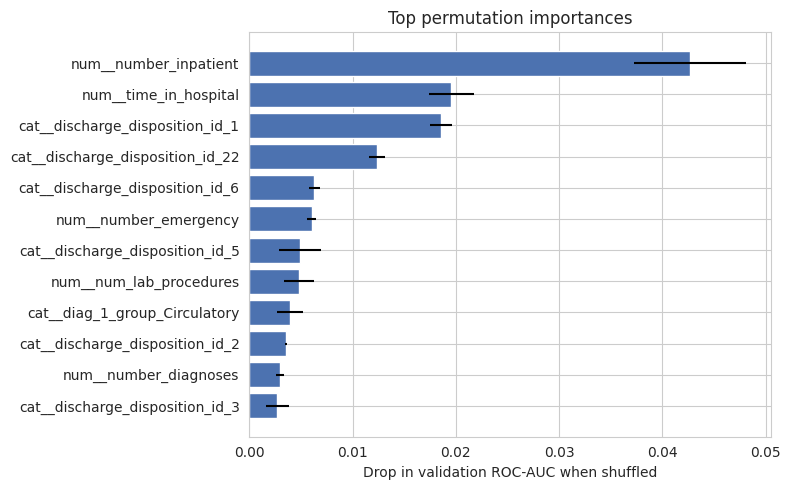

In [42]:
# ==============================================================================
# SECTION: Interpretability: permutation importance
# Shuffles each feature on a validation sample and measures the drop in ROC-
# AUC to rank the most important features.
# ==============================================================================
from sklearn.inspection import permutation_importance

prep_f, clf_f = final_pipe.named_steps["prep"], final_pipe.named_steps["clf"]
Xv_t = prep_f.transform(X_val)
feat_names = prep_f.get_feature_names_out()
rng = np.random.RandomState(RANDOM_SEED)
sample_idx = rng.choice(Xv_t.shape[0], size=2500, replace=False)
pi = permutation_importance(clf_f, Xv_t[sample_idx], y_val.values[sample_idx], n_repeats=3,
                            random_state=RANDOM_SEED, scoring="roc_auc", n_jobs=1)
imp = pd.DataFrame({"feature": feat_names, "importance_mean": pi.importances_mean,
                    "importance_std": pi.importances_std}).sort_values("importance_mean", ascending=False)
top = imp.head(12).iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(top["feature"], top["importance_mean"], xerr=top["importance_std"], color="#4C72B0")
ax.set_xlabel("Drop in validation ROC-AUC when shuffled"); ax.set_title("Top permutation importances")
plt.tight_layout(); save_fig()
print(imp.head(10).round(5).to_string(index=False))

**Discussion.** Read the table above: the largest drops should come from prior-utilization (`number_inpatient`, matching the EDA) and discharge-disposition categories, followed by smaller contributions from other features.
Permutation importance shows a feature's **contribution to predictive performance, not a causal effect** — e.g., a transfer-to-rehab disposition likely
reflects patient acuity, not that the transfer causes readmission. Per-patient explanations come from the SHAP cell below when it runs (Colab); otherwise they are future work.

### SHAP explanations **[Colab only]**
SHAP's `TreeExplainer` supports XGBoost/LightGBM (not scikit-learn's histogram boosting), so the SHAP summary is computed on the XGBoost candidate when it is available.
It explains *that* model, not necessarily the selected final model.

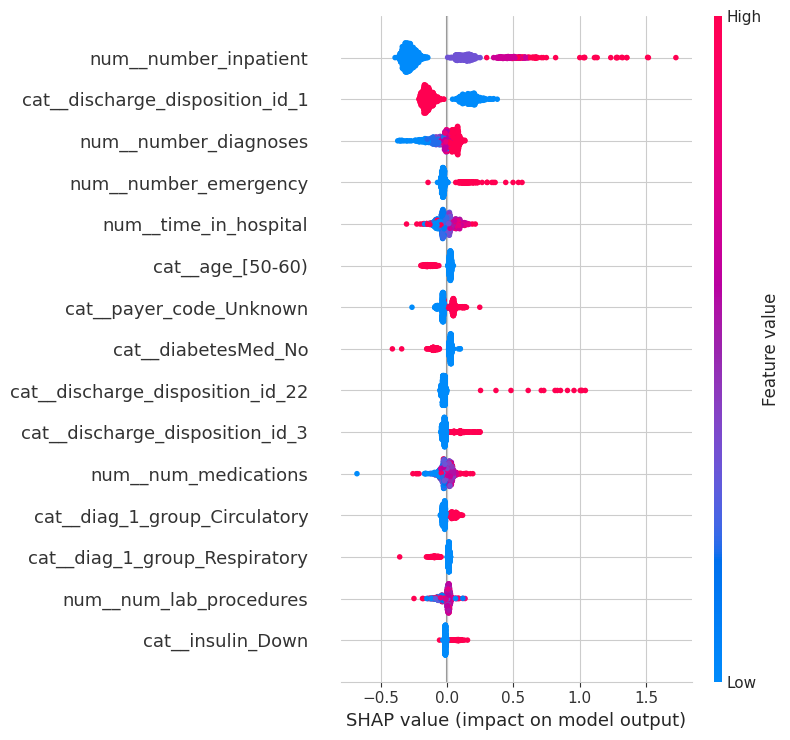

In [43]:
# ==============================================================================
# SECTION: SHAP explanations (Colab)
# Computes SHAP values for the XGBoost model on 1000 validation rows and draws
# the summary plot; skipped if unavailable.
# ==============================================================================
if HAS_SHAP and "XGBoost" in extra_models:
    import shap
    pre_x, clf_x = extra_models["XGBoost"].named_steps["prep"], extra_models["XGBoost"].named_steps["clf"]
    Xs = pre_x.transform(X_val.sample(1000, random_state=RANDOM_SEED))
    sv = shap.TreeExplainer(clf_x).shap_values(Xs)
    shap.summary_plot(sv, Xs, feature_names=pre_x.get_feature_names_out(), max_display=15, show=False)
    plt.tight_layout(); save_fig()
else:
    print("SHAP skipped: needs the `shap` package and the XGBoost candidate (run in Colab).")

## Comparison with an earlier development build (informational)
Before the Colab run, the same code was tested offline (scikit-learn 1.9.1, no XGBoost/LightGBM), which selected HistGradientBoosting. The cell below shows how this run differs. Differences are expected (different library versions, and XGBoost/LightGBM now compete); **use this run's numbers.**

In [44]:
# ==============================================================================
# SECTION: Comparison with the offline build
# Prints whether this run matches the reference numbers from the offline build
# (informational only).
# ==============================================================================
REF = {"selected_model": "HistGradientBoosting (primary, tuned)", "chosen_threshold": 0.51, "final_test_metrics": {"roc_auc": 0.6822, "pr_auc": 0.236, "recall": 0.5491, "precision": 0.1929, "f1": 0.2855, "accuracy": 0.6891, "confusion_matrix": [[9316, 3862], [758, 923]], "threshold_used": 0.51, "brier_score": 0.2162}}
checks = {
    "selected model": (best_name.split(" (")[0] in REF["selected_model"], best_name, REF["selected_model"]),
    "threshold": (abs(final_threshold - REF["chosen_threshold"]) < 1e-9, final_threshold, REF["chosen_threshold"]),
    "test ROC-AUC": (test_metrics["roc_auc"] == REF["final_test_metrics"]["roc_auc"], test_metrics["roc_auc"], REF["final_test_metrics"]["roc_auc"]),
    "test PR-AUC": (test_metrics["pr_auc"] == REF["final_test_metrics"]["pr_auc"], test_metrics["pr_auc"], REF["final_test_metrics"]["pr_auc"]),
    "test recall": (test_metrics["recall"] == REF["final_test_metrics"]["recall"], test_metrics["recall"], REF["final_test_metrics"]["recall"]),
    "confusion matrix": (test_metrics["confusion_matrix"] == REF["final_test_metrics"]["confusion_matrix"], test_metrics["confusion_matrix"], REF["final_test_metrics"]["confusion_matrix"]),
}
for name, (ok, mine, theirs) in checks.items():
    print(f"{'MATCH   ' if ok else 'DIFFERS '} {name}: this run={mine} | reference run={theirs}")
print("\nA DIFFERENCE is expected when the library versions differ or XGBoost/LightGBM take part in model selection; it is not an error by itself.")

DIFFERS  selected model: this run=LightGBM | reference run=HistGradientBoosting (primary, tuned)
MATCH    threshold: this run=0.51 | reference run=0.51
DIFFERS  test ROC-AUC: this run=0.6856 | reference run=0.6822
DIFFERS  test PR-AUC: this run=0.239 | reference run=0.236
DIFFERS  test recall: this run=0.5289 | reference run=0.5491
DIFFERS  confusion matrix: this run=[[9653, 3525], [792, 889]] | reference run=[[9316, 3862], [758, 923]]

A DIFFERENCE is expected when the library versions differ or XGBoost/LightGBM take part in model selection; it is not an error by itself.


# Task 8 — Test the Solution

## 8.1 Save the final model and build the shared inference function
The same function `predict_one()` is used by the tests and by the prototype form below. Risk-tier cut points are the 50th/85th percentiles of validation scores
(class weighting inflates raw probabilities, so absolute cut points such as 0.10/0.30 would be meaningless).

In [45]:
# ==============================================================================
# SECTION: Save the model and build the prediction function
# Computes risk-tier cut points, saves the model and metadata to the models/
# folder, defines input validation and predict_one(), and checks the reloaded
# model.
# ==============================================================================
tier_cuts = [round(float(v), 2) for v in np.percentile(final_val_prob, [50, 85])]
print("Risk-tier cut points from validation percentiles (50th, 85th):", tier_cuts)

metadata = {"model_name": best_name, "decision_threshold": final_threshold,
            "risk_tier_thresholds": {"low_below": tier_cuts[0], "medium_below": tier_cuts[1]},
            "feature_list": list(X_train.columns), "random_seed": RANDOM_SEED, "sklearn_version": sklearn.__version__,
            "numeric_ranges": {c: [float(X_train[c].min()), float(X_train[c].max())] for c in NUMERIC_FEATURES},
            "categories": {c: sorted(X_train[c].astype(str).unique().tolist()) for c in OTHER_CATEGORICAL},
            "evaluation_metrics_test_set": test_metrics}
joblib.dump(final_pipe, MODEL_DIR / "final_model.joblib")
json.dump(metadata, open(MODEL_DIR / "model_metadata.json", "w"), indent=2, default=str)
print("Saved:", sorted(p.name for p in MODEL_DIR.iterdir()))
json.dump({"selected_model": best_name, "threshold": final_threshold, "test_metrics": test_metrics,
           "validation_comparison": comparison.round(4).to_dict(), "success_criteria": success.astype(str).to_dict("records")},
          open(OUT_DIR / "results" / "notebook_results.json", "w"), indent=2, default=str)
print("Results written to", OUT_DIR / "results" / "notebook_results.json")

REQUIRED_FEATURES = NUMERIC_FEATURES + OTHER_CATEGORICAL
DISCLAIMER = ("This prototype is for academic and research demonstration purposes only. It is not a medical diagnosis, does not replace "
              "professional clinical judgment, and has not been clinically validated for real-world patient care.")

def validate_record(record):
    problems = [f"Missing required field: {c}" for c in REQUIRED_FEATURES if c not in record]
    for c in NUMERIC_FEATURES:
        if c in record and record[c] is not None:
            try: float(record[c])
            except (TypeError, ValueError): problems.append(f"Field '{c}' must be numeric, got {record[c]!r}")
    return (len(problems) == 0), problems

_model = joblib.load(MODEL_DIR / "final_model.joblib")      # load from disk, exactly as a deployed app would
_meta = json.load(open(MODEL_DIR / "model_metadata.json"))

def predict_one(record):
    # raw feature dict -> probability + tier. Missing fields are imputed by the pipeline (train-fit imputers); bad numerics become NaN.
    _, problems = validate_record(record)
    df1 = pd.DataFrame([{c: record.get(c, None) for c in REQUIRED_FEATURES}])
    for c in NUMERIC_FEATURES:
        df1[c] = pd.to_numeric(df1[c], errors="coerce")
        v = df1[c].iloc[0]
        lo, hi = _meta["numeric_ranges"][c]
        if pd.notna(v) and not (lo <= v <= hi):
            problems.append(f"Value {v:g} for '{c}' is outside the range seen in training ({lo:g}-{hi:g}); the prediction may be unreliable")
    for c in OTHER_CATEGORICAL:
        v = record.get(c)
        if v is not None and str(v) not in _meta["categories"][c]:
            problems.append(f"Unexpected category {str(v)!r} for '{c}' (not seen in training); it is treated as unknown")
        if c in ID_CODED_CATEGORICAL and v is not None:
            df1[c] = str(v)
    prob = float(_model.predict_proba(df1)[:, 1][0])
    t = _meta["risk_tier_thresholds"]
    return {"probability_30d_readmission": round(prob, 4),
            "risk_tier": risk_tier(prob, low_cut=t["low_below"], high_cut=t["medium_below"]),
            "predicted_high_risk_flag": bool(prob >= _meta["decision_threshold"]),
            "decision_threshold_used": _meta["decision_threshold"],
            "input_warnings": problems if problems else None, "disclaimer": DISCLAIMER}

same = np.allclose(_model.predict_proba(X_test)[:, 1], test_prob)
print("Model reloaded from disk gives identical test predictions:", bool(same))

Risk-tier cut points from validation percentiles (50th, 85th): [0.42, 0.6]
Saved: ['final_model.joblib', 'model_metadata.json']
Results written to /content/drive/MyDrive/Module5_AI_Project/outputs/results/notebook_results.json
Model reloaded from disk gives identical test predictions: True


## 8.2 End-to-end test cases
The whole chain is tested: input → validation → preprocessing → model → prediction → output. The first five rows are the guideline's required cases; rows 6–7 check that ranking behaves sensibly.
Normal / higher / lower cases are real (de-identified) test-set rows at the 65th, 95th and 10th percentile of predicted risk. Expectations are written *before* the result; PASS/FAIL is computed.

In [46]:
# ==============================================================================
# SECTION: End-to-end test cases
# Runs 7 cases through the whole chain (normal, missing, invalid, unexpected
# category, extreme, higher-risk, lower-risk) and prints PASS/FAIL.
# ==============================================================================
order = np.argsort(test_prob)
pick = lambda q: X_test.iloc[order[int(q * len(order))]].to_dict()
typical, higher, lower = pick(0.65), pick(0.95), pick(0.10)
missing_rec = {k: v for k, v in typical.items() if k != "number_inpatient"}             # one required field left out
invalid_rec = dict(typical, num_medications="not_a_number")                              # wrong format
unexpected = dict(typical, race="Martian", insulin="Sideways")                           # categories never seen in training
extreme = dict(typical, time_in_hospital=60, num_medications=300, number_inpatient=90, num_lab_procedures=500)

R = {n: predict_one(r) for n, r in [("normal", typical), ("missing", missing_rec), ("invalid", invalid_rec), ("unexpected", unexpected),
                                    ("extreme", extreme), ("higher", higher), ("lower", lower)]}
P = {k: v["probability_30d_readmission"] for k, v in R.items()}
def valid(r): return 0.0 <= r["probability_30d_readmission"] <= 1.0 and r["risk_tier"] in {"Low", "Medium", "High"}
def warned(r, text): return bool(r["input_warnings"]) and any(text in w for w in r["input_warnings"])

table = pd.DataFrame([
    ("1 Normal, complete input", "real test-set row (65th pct)", "valid score + tier, no warnings", f"p={P['normal']}, tier={R['normal']['risk_tier']}, warnings={R['normal']['input_warnings']}",
     valid(R["normal"]) and R["normal"]["input_warnings"] is None),
    ("2 Missing value", "`number_inpatient` omitted", "clear message; no crash", f"p={P['missing']}; {R['missing']['input_warnings']}",
     valid(R["missing"]) and warned(R["missing"], "Missing required field: number_inpatient")),
    ("3 Invalid number / format", "`num_medications` = 'not_a_number'", "rejected safely: warning, no crash", f"p={P['invalid']}; {R['invalid']['input_warnings']}",
     valid(R["invalid"]) and warned(R["invalid"], "num_medications")),
    ("4 Unexpected category", "race='Martian', insulin='Sideways'", "handled: warning, treated as unknown", f"p={P['unexpected']}; {R['unexpected']['input_warnings']}",
     valid(R["unexpected"]) and warned(R["unexpected"], "Unexpected category 'Martian'")),
    ("5 Extreme value", "60-day stay, 300 meds, 90 prior inpatient, 500 labs", "handled and warned (outside training range)", f"p={P['extreme']}, tier={R['extreme']['risk_tier']}; {len(R['extreme']['input_warnings'] or [])} warnings",
     valid(R["extreme"]) and warned(R["extreme"], "outside the range seen in training")),
    ("6 Higher-risk case", "real row, 95th pct", "High tier and p > normal", f"p={P['higher']}, tier={R['higher']['risk_tier']}",
     R["higher"]["risk_tier"] == "High" and P["higher"] > P["normal"]),
    ("7 Lower-risk case", "real row, 10th pct", "Low tier and p < normal", f"p={P['lower']}, tier={R['lower']['risk_tier']}",
     R["lower"]["risk_tier"] == "Low" and P["lower"] < P["normal"]),
], columns=["Test case", "Input", "Expected", "Actual", "Passed"])
table["Pass / Fail"] = np.where(table["Passed"], "PASS", "FAIL")
print(table.drop(columns="Passed").to_string(index=False))
print("\nAll workflow test cases passed:", bool(table["Passed"].all()))

                Test case                                               Input                                    Expected                                                                                                                                                                                                   Actual Pass / Fail
 1 Normal, complete input                        real test-set row (65th pct)             valid score + tier, no warnings                                                                                                                                                                     p=0.4857, tier=Medium, warnings=None        PASS
          2 Missing value                          `number_inpatient` omitted                     clear message; no crash                                                                                                                                                   p=0.4857; ['Missing required field: number_inpatient']        

## 8.3 Automated unit tests (inside the notebook)
Plain `assert` functions, collected and run below with pytest-style PASS/FAIL reporting. (The project zip also contains `tests/test_project.py` for `pytest` on a local machine.)

In [47]:
# ==============================================================================
# SECTION: Unit tests
# Small automated tests of grouping, exclusions, missing-value handling, risk
# tiers, leakage and prediction output; the notebook stops if any fails.
# ==============================================================================
def test_icd9_grouping():
    assert icd9_to_category("250.01") == "Diabetes" and icd9_to_category("410") == "Circulatory"
    assert icd9_to_category("786.05") == "Respiratory" and icd9_to_category("459.81") == "Circulatory"
    assert icd9_to_category("787.01") == "Digestive" and icd9_to_category("788.1") == "Genitourinary"
    assert icd9_to_category("249.00") == "Other" and icd9_to_category("V27") == "Other"
    assert icd9_to_category("?") == "Missing" and icd9_to_category(None) == "Missing"

def test_target_and_exclusions():
    raw_t = pd.DataFrame({"readmitted": ["<30", ">30", "NO", "NO"], "discharge_disposition_id": [1, 1, 11, 1],
                          "gender": ["Female", "Male", "Female", "Unknown/Invalid"], "encounter_id": [1, 2, 3, 4], "patient_nbr": [1, 2, 3, 4]})
    out_t = apply_target_and_exclusions(raw_t)
    assert out_t[TARGET_COL].tolist() == [1, 0]          # expired (11) and Unknown/Invalid gender removed

def test_missing_markers():
    d = pd.DataFrame({"payer_code": ["?", "MC"], "medical_specialty": ["?", "X"], "race": ["?", "Caucasian"],
                      "max_glu_serum": [None, ">200"], "A1Cresult": [None, "Norm"]})
    o = clean_missing_markers(d)
    assert o["payer_code"].tolist() == ["Unknown", "MC"] and o["max_glu_serum"].tolist() == ["Not tested", ">200"]

def test_risk_tier_boundaries():
    assert risk_tier(0.0) == "Low" and risk_tier(0.45) == "Medium" and risk_tier(0.60) == "High"

def test_no_identifiers_as_features():
    assert "patient_nbr" not in X.columns and "encounter_id" not in X.columns and "patient_nbr" not in _meta["feature_list"]

def test_no_patient_leakage():
    assert not (p_tr & p_va) and not (p_tr & p_te) and not (p_va & p_te)

def test_prediction_output_format():
    r = predict_one(typical)
    assert 0.0 <= r["probability_30d_readmission"] <= 1.0 and r["risk_tier"] in {"Low", "Medium", "High"}
    assert isinstance(r["predicted_high_risk_flag"], bool) and len(r["disclaimer"]) > 0

def test_prediction_missing_and_invalid_input():
    r = predict_one({}); assert r["input_warnings"] and 0.0 <= r["probability_30d_readmission"] <= 1.0
    bad = dict(typical, num_medications="not_a_number")
    r = predict_one(bad); assert any("num_medications" in w for w in r["input_warnings"])

def test_extreme_value_and_unexpected_category_warn():
    assert warned(predict_one(extreme), "outside the range seen in training")
    r = predict_one(unexpected); assert warned(r, "Unexpected category") and 0.0 <= r["probability_30d_readmission"] <= 1.0

def test_higher_risk_ranks_above_lower_risk():
    assert predict_one(higher)["probability_30d_readmission"] > predict_one(lower)["probability_30d_readmission"]

tests = [(k, v) for k, v in sorted(globals().items()) if k.startswith("test_") and callable(v)]
failed = []
for name, fn in tests:
    try:
        fn(); print("PASS", name)
    except Exception as e:
        failed.append(name); print("FAIL", name, "->", repr(e))
print(f"\n{len(tests) - len(failed)} / {len(tests)} tests passed")
assert not failed, failed

PASS test_extreme_value_and_unexpected_category_warn
PASS test_higher_risk_ranks_above_lower_risk
PASS test_icd9_grouping
PASS test_missing_markers
PASS test_no_identifiers_as_features
PASS test_no_patient_leakage
PASS test_prediction_missing_and_invalid_input
PASS test_prediction_output_format
PASS test_risk_tier_boundaries
PASS test_target_and_exclusions

10 / 10 tests passed


## 8.4 Working prototype (in-notebook form) **[Colab only]**
A small `ipywidgets` form: pick a real sample case, optionally edit key fields, press **Predict**. Everything not shown on the form keeps the sample case's value.
Outside Colab/Jupyter (no `ipywidgets`), the cell instead prints the prototype's output for one sample case so the same code path is still exercised.

In [48]:
# ==============================================================================
# SECTION: Prototype form
# ipywidgets form to choose a sample case, edit key fields and press Predict;
# prints a sample result if widgets are unavailable.
# ==============================================================================
SAMPLES = {"Typical case (65th pct)": typical, "Higher-risk case (95th pct)": higher, "Lower-risk case (10th pct)": lower}

def show_result(r):
    print(f"30-day readmission score : {r['probability_30d_readmission']:.1%}  (relative score - NOT a literal real-world probability)")
    print(f"Risk tier                : {r['risk_tier']}   | flagged at threshold {r['decision_threshold_used']}: {r['predicted_high_risk_flag']}")
    if r["input_warnings"]: print("Warnings:", *r["input_warnings"][:5], sep="\n  - ")
    print("\n" + r["disclaimer"])

try:
    if not HAS_WIDGETS: raise ImportError("ipywidgets not installed")
    import ipywidgets as W
    from IPython.display import display, clear_output
    case = W.Dropdown(options=list(SAMPLES), description="Sample case")
    age = W.Dropdown(options=sorted(X["age"].unique()), description="Age band")
    los = W.IntSlider(min=1, max=14, description="Days in hospital")
    nmed = W.IntSlider(min=1, max=81, description="# medications")
    ninp = W.IntSlider(min=0, max=15, description="Prior inpatient")
    nemr = W.IntSlider(min=0, max=20, description="Prior emergency")
    ndx = W.IntSlider(min=1, max=16, description="# diagnoses")
    ins = W.Dropdown(options=sorted(X["insulin"].unique()), description="Insulin")
    a1c = W.Dropdown(options=sorted(X["A1Cresult"].unique()), description="A1C result")
    btn, out_w = W.Button(description="Predict", button_style="primary"), W.Output()

    def _load(_=None):
        rec = SAMPLES[case.value]
        age.value, los.value, nmed.value = rec["age"], int(rec["time_in_hospital"]), int(rec["num_medications"])
        ninp.value, nemr.value, ndx.value = int(rec["number_inpatient"]), int(rec["number_emergency"]), int(rec["number_diagnoses"])
        ins.value, a1c.value = rec["insulin"], rec["A1Cresult"]
    def _predict(_):
        rec = dict(SAMPLES[case.value], age=age.value, time_in_hospital=los.value, num_medications=nmed.value, number_inpatient=ninp.value,
                   number_emergency=nemr.value, number_diagnoses=ndx.value, insulin=ins.value, A1Cresult=a1c.value)
        with out_w:
            clear_output(); show_result(predict_one(rec))
    case.observe(_load, names="value"); btn.on_click(_predict); _load()
    display(W.VBox([case, age, los, nmed, ninp, nemr, ndx, ins, a1c, btn, out_w]))
except ImportError as e:
    print(f"[widgets unavailable here: {e}] Printing the prototype output for one sample case instead:\n")
    show_result(predict_one(SAMPLES["Higher-risk case (95th pct)"]))

## 8.5 Download the trained model **[Colab only]**
The model and metadata are already saved in your Drive folder (`Module5_AI_Project/models/`). In Colab this cell also downloads them to your computer (load with `joblib.load`; use the same scikit-learn version shown in the setup cell).

In [49]:
# ==============================================================================
# SECTION: Download the trained model
# In Colab, downloads final_model.joblib and model_metadata.json to your
# computer.
# ==============================================================================
if IN_COLAB:
    from google.colab import files
    files.download(str(MODEL_DIR / "final_model.joblib")); files.download(str(MODEL_DIR / "model_metadata.json"))
else:
    print("Not running in Colab - the files are saved in:", MODEL_DIR)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# Final Documentation and Submission

**Report structure (guideline) → where it is covered.** The full written report is `PROJECT_REPORT` (md/docx/pdf in the project folder); this notebook is the working evidence.

| # | Guideline section | In this notebook |
|---|---|---|
| 1–4 | Title, problem statement, target users, proposed AI solution | Title; Tasks 1–2 |
| 5 | Dataset | 3.0.3 |
| 6 | Data preparation | Task 3 (problem log 3.2.1, preprocessing record 3.5) |
| 7 | Exploratory data analysis | Task 4 (findings table and summary) |
| 8–9 | Baseline model; model improvement | Tasks 5–6 (tuning log, overfitting check, decision 6.5) |
| 10–11 | Final model; evaluation | Task 7 |
| 12–13 | Testing; working prototype | Task 8 (8.2 test cases, 8.4 prototype form) |
| 14–16 | Limitations and responsible use; future improvements; conclusion | Task 7 discussion; Final Conclusion below |
| 17 | Team contributions | table below |

**Team contributions** (participating members, by area, following the responsibility table in the approved Module 4 proposal):

| Area | Members |
|---|---|
| Domain / problem research — problem framing, clinical context, references | Fisehatsion Adisu, Birhan Getachew, Asmelash Abriham, Fasikaw Lakew |
| Data discovery / preparation — cleaning, encoding, EDA, patient-grouped split | Daniel Asele, Tsegaye Abate |
| ML/DL development — baseline and candidate models, tuning, evaluation | Fisehatsion Adisu, Addis Misgana |
| Application implementation — prediction function and prototype interface | Tewoderos Adare |
| Deployment / testing — test cases and end-to-end workflow testing | Abrham Mekbib, Asmelash Abriham |
| Documentation / presentation — report, README, discussion posts | Abraham |

**Group reflection**

- **What did we learn?** That the evaluation set-up matters as much as the model. Many patients have several encounters (23.5% of patients), so a random row split would have leaked patients across the training and test sets; we split by patient. Accuracy is misleading here (always predicting “no readmission” scores 88.4%), so we judged models by ROC-AUC, PR-AUC and recall. A more complex model did not automatically help: the five models were within about 0.01 ROC-AUC of each other, and most of the signal comes from prior inpatient visits, which logistic regression already captures.
- **What was the most difficult part?** Judging the results honestly. The final model beats the logistic baseline by only 1.71%, two success criteria are met by thin margins, the scores are poorly calibrated, and 97% of the missed readmissions were patients with zero or one prior inpatient visit. Reporting this plainly, rather than presenting the model as a success, was the hardest part.
- **What technical problem did we encounter and how did we solve it?** Three problems came up when running the notebook in Colab. (1) Google Drive failed to mount in one run, so files went to the temporary session folder; the notebook now retries once and explains the fallback, and a re-run with Drive mounted gave identical results. (2) An early run left XGBoost and LightGBM out of model selection and picked logistic regression on a tie; we changed the notebook so all five models compete. (3) The model-comparison chart failed with a shape mismatch because three bar labels were hard-coded for five models; the labels and colours are now built from the comparison table.
- **What would we improve with more time?** Recalibrate the scores (Platt or isotonic), tune XGBoost and LightGBM with cross-validation and compare repeated splits to see whether the near-tie holds, add features that help first-time high-risk patients, run a fuller fairness check with larger subgroups, validate on newer or external data, and add per-patient SHAP explanations to the app.
- **What did we learn about working as a team?** Agreeing early on the scope and the dataset made the later work smoother, and outside review improved the result: feedback on the Module 4 proposal led us to add calibration, a not-clinically-validated disclaimer and more careful wording about the data. Roles are easiest to carry out when each person confirms the area they will work on, and the contribution list should match who actually took part.


# Final Conclusion

In [50]:
# ==============================================================================
# SECTION: Final conclusion
# Prints the final model, test results, number of criteria met and the main
# limitations, from this run's own numbers.
# ==============================================================================
n_met = int(success["met"].sum())
print("The notebook ran the full flow: Problem -> Data -> Analysis -> Model -> Evaluation -> Testing -> Working Prototype, on the real dataset,")
print("with a patient-level leakage-safe split, a class-weighted logistic-regression baseline, improved candidates, a single test-set evaluation, and tested end-to-end inference.\n")
print(f"Final model: {best_name}")
print(f"Held-out, patient-disjoint test set (evaluated once; threshold {final_threshold}): ROC-AUC {test_metrics['roc_auc']}, PR-AUC {test_metrics['pr_auc']}, "
      f"recall {test_metrics['recall']}, precision {test_metrics['precision']}.")
print(f"Module 4 success criteria met: {n_met} of {len(success)}. Not met: {', '.join(success.loc[~success['met'], 'criterion']) or 'none'}.")
print("\nRaw scores are poorly calibrated (class weighting), so the tiers express RELATIVE risk, not literal probability. The data are U.S. hospital records from 1999-2008 with no")
print("external or clinical validation: this is a research/educational decision-support prototype only. See PROJECT_REPORT (project zip) for limitations, ethics and future work.")

The notebook ran the full flow: Problem -> Data -> Analysis -> Model -> Evaluation -> Testing -> Working Prototype, on the real dataset,
with a patient-level leakage-safe split, a class-weighted logistic-regression baseline, improved candidates, a single test-set evaluation, and tested end-to-end inference.

Final model: LightGBM
Held-out, patient-disjoint test set (evaluated once; threshold 0.51): ROC-AUC 0.6856, PR-AUC 0.239, recall 0.5289, precision 0.2014.
Module 4 success criteria met: 5 of 6. Not met: AUC gain vs. logistic regression (%).

Raw scores are poorly calibrated (class weighting), so the tiers express RELATIVE risk, not literal probability. The data are U.S. hospital records from 1999-2008 with no
external or clinical validation: this is a research/educational decision-support prototype only. See PROJECT_REPORT (project zip) for limitations, ethics and future work.
